In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
import os
import zipfile

drive.mount('/content/drive')

drive_path = "/content/drive/MyDrive"

if not os.path.exists(drive_path):
    raise FileNotFoundError("Google Drive is not mounted correctly.")

print("Google Drive connected successfully.")

zip_name = "dataset_deep learning - Copy.zip"

zip_path = None

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file == zip_name:
            zip_path = os.path.join(root, file)
            break
    if zip_path:
        break

if zip_path is None:
    raise FileNotFoundError(
        f"Could not find '{zip_name}' anywhere inside Google Drive."
    )

print("\nUsing ZIP file:")
print(zip_path)

extract_to = "/content/dataset"

os.makedirs(extract_to, exist_ok=True)

print("\nExtracting dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_to)

print("Dataset extracted successfully.")

dataset_path = None

for root, dirs, files in os.walk(extract_to):
    for folder in dirs:
        if folder == "COVID-19_Radiography_Dataset":
            dataset_path = os.path.join(root, folder)
            break
    if dataset_path:
        break

if dataset_path:
    print("\n========================================")
    print("DATASET FOUND SUCCESSFULLY!")
    print("========================================")
    print(dataset_path)

else:
    print("\nWARNING: COVID-19_Radiography_Dataset was not found.")

    print("\nFolders inside /content/dataset:")

    for root, dirs, files in os.walk(extract_to):
        level = root.replace(extract_to, "").count(os.sep)
        indent = "  " * level
        print(indent + os.path.basename(root) + "/")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully.

Using ZIP file:
/content/drive/MyDrive/dataset_deep learning - Copy.zip

Extracting dataset...
Dataset extracted successfully.

DATASET FOUND SUCCESSFULLY!
/content/dataset/COVID-19_Radiography_Dataset


In [ ]:
import os

DATASET_PATH = "/content/dataset/COVID-19_Radiography_Dataset"

classes = [
    c for c in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, c))
]

for c in classes:
    folder_path = os.path.join(DATASET_PATH, c, "images")

    if not os.path.exists(folder_path):
        print(f"{c} : Not found")
        continue

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ]

    print(c, ":", len(images), "Img")

Lung_Opacity : 6012 Img
Normal : 10192 Img
Viral Pneumonia : 1345 Img
COVID : 3616 Img


In [ ]:
import os
import random
from collections import Counter
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from rich.console import Console
from rich.table import Table


In [ ]:

random.seed(42)

DATASET_PATH = "/content/dataset/COVID-19_Radiography_Dataset"

IMAGE_EXTENSIONS = ('.png', '.jpg', '.jpeg')

MAX_IMAGES_PER_CLASS = 3000

TARGET_TOTAL_IMAGES = None

console = Console()


def get_all_images(folder_path):

    images = []

    for root, _, files in os.walk(folder_path):

        for f in files:

            if f.lower().endswith(IMAGE_EXTENSIONS):

                images.append(os.path.join(root, f))

    return images



def downsample(images, max_images):

    if len(images) <= max_images:
        return images

    return random.sample(images, max_images)


all_class_images = {}

for cls in os.listdir(DATASET_PATH):

    class_path = os.path.join(DATASET_PATH, cls, "images")

    if not os.path.isdir(class_path):
        continue

    images = get_all_images(class_path)

    if cls in ["Normal", "Lung_Opacity"]:
        images = downsample(images, MAX_IMAGES_PER_CLASS)

    all_class_images[cls] = images


total_images = sum(
    len(imgs)
    for imgs in all_class_images.values()
)


table = Table(
    title=f"Final Dataset (≈{TARGET_TOTAL_IMAGES} images)",
    style="black"
)

table.add_column(
    "Class",
    style="bold black"
)

table.add_column(
    "Number of Images",
    justify="right",
    style="bold deep_pink4"
)


for cls, imgs in all_class_images.items():

    table.add_row(
        cls,
        str(len(imgs))
    )


console.print(table)

print(f"Total images: {total_images}")

     Final Dataset (≈None images)     
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ Class           ┃ Number of Images ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ Lung_Opacity    │             3000 │
│ Normal          │             3000 │
│ Viral Pneumonia │             1345 │
│ COVID           │             3616 │
└─────────────────┴──────────────────┘

Total images: 10961


In [ ]:
import os
import random
import copy
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

DATASET_PATH = "/content/dataset/COVID-19_Radiography_Dataset"

IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMAGE_SIZE = (256, 256)

EPOCHS = 10

BATCH_SIZE = 32

BEST_MODEL_PATH = "/content/best_unet.pth"

FINAL_CLASS_COUNTS = {
    "COVID": 3616,
    "Lung_Opacity": 3000,
    "Normal": 3000,
    "Viral Pneumonia": 1345
}

print("Device:", DEVICE)


def get_all_images(folder_path):
    images = []

    for root, _, files in os.walk(folder_path):
        for f in files:
            if f.lower().endswith(IMAGE_EXTENSIONS):
                images.append(os.path.join(root, f))

    return sorted(images)


all_class_images = {}

for cls in FINAL_CLASS_COUNTS:
    class_path = os.path.join(DATASET_PATH, cls)
    images_folder = os.path.join(class_path, "images")

    images = get_all_images(images_folder)

    if len(images) < FINAL_CLASS_COUNTS[cls]:
        raise ValueError(
            f"{cls}: requested {FINAL_CLASS_COUNTS[cls]} images, "
            f"but only {len(images)} are available."
        )

    all_class_images[cls] = images


final_sample = {}

for cls, target_count in FINAL_CLASS_COUNTS.items():
    final_sample[cls] = random.sample(
        all_class_images[cls],
        target_count
    )


print("\nFinal Dataset:")

for cls, images in final_sample.items():
    print(f"{cls}: {len(images)} images")

total_images = sum(
    len(images)
    for images in final_sample.values()
)

print(f"Total images: {total_images}")


def build_image_mask_lists(sampled_dict):
    image_paths = []
    mask_paths = []
    labels = []

    class_to_idx = {
        "COVID": 0,
        "Lung_Opacity": 1,
        "Normal": 2,
        "Viral Pneumonia": 3
    }

    for cls, images in sampled_dict.items():
        for img in images:
            mask = img.replace(
                os.sep + "images" + os.sep,
                os.sep + "masks" + os.sep
            )

            if not os.path.exists(mask):
                raise FileNotFoundError(
                    f"Mask not found: {mask}"
                )

            image_paths.append(img)
            mask_paths.append(mask)
            labels.append(class_to_idx[cls])

    return image_paths, mask_paths, labels


image_paths, mask_paths, labels = build_image_mask_lists(
    final_sample
)


class LungDataset(Dataset):

    def __init__(
        self,
        image_paths,
        mask_paths,
        transform=None
    ):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image = Image.open(
            self.image_paths[idx]
        ).convert("L")

        mask = Image.open(
            self.mask_paths[idx]
        ).convert("L")

        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        mask = (mask > 0.5).float()

        return image, mask


transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor()
])


dataset = LungDataset(
    image_paths,
    mask_paths,
    transform
)


indices = np.arange(len(dataset))
labels = np.array(labels)

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

temp_labels = labels[temp_indices]

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)


train_ds = Subset(
    dataset,
    train_indices.tolist()
)

val_ds = Subset(
    dataset,
    val_indices.tolist()
)

test_ds = Subset(
    dataset,
    test_indices.tolist()
)


print("\nDataset Split:")
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))


print("\nClass Distribution:")

for cls, idx in {
    "COVID": 0,
    "Lung_Opacity": 1,
    "Normal": 2,
    "Viral Pneumonia": 3
}.items():

    train_count = np.sum(
        labels[train_indices] == idx
    )

    val_count = np.sum(
        labels[val_indices] == idx
    )

    test_count = np.sum(
        labels[test_indices] == idx
    )

    print(
        f"{cls}: "
        f"Train={train_count}, "
        f"Val={val_count}, "
        f"Test={test_count}"
    )


class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.enc1 = nn.Sequential(
            nn.Conv2d(
                1,
                64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                64,
                64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(
                128,
                256,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                256,
                256,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec2 = nn.Sequential(
            nn.Conv2d(
                256,
                128,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec1 = nn.Sequential(
            nn.Conv2d(
                128,
                64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

        self.out = nn.Conv2d(
            64,
            1,
            kernel_size=1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool1(e1)
        )

        b = self.bottleneck(
            self.pool2(e2)
        )

        d2 = self.dec2(
            torch.cat(
                [
                    self.up2(b),
                    e2
                ],
                dim=1
            )
        )

        d1 = self.dec1(
            torch.cat(
                [
                    self.up1(d2),
                    e1
                ],
                dim=1
            )
        )

        return torch.sigmoid(
            self.out(d1)
        )


def dice_coefficient(
    pred,
    target,
    smooth=1.0
):

    pred = (
        pred > 0.5
    ).float()

    intersection = (
        pred * target
    ).sum(
        dim=(2, 3)
    )

    dice = (
        2 * intersection + smooth
    ) / (
        pred.sum(dim=(2, 3))
        +
        target.sum(dim=(2, 3))
        +
        smooth
    )

    return dice.mean().item()


def iou_score(
    pred,
    target,
    smooth=1.0
):

    pred = (
        pred > 0.5
    ).float()

    intersection = (
        pred * target
    ).sum(
        dim=(2, 3)
    )

    union = (
        pred.sum(dim=(2, 3))
        +
        target.sum(dim=(2, 3))
        -
        intersection
    )

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )

    return iou.mean().item()


def calc_accuracy(
    pred,
    target
):

    pred = (
        pred > 0.5
    ).float()

    return (
        (pred == target)
        .float()
        .mean()
        .item()
    )


def dice_loss(
    pred,
    target,
    smooth=1.0
):

    intersection = (
        pred * target
    ).sum(
        dim=(2, 3)
    )

    dice = (
        2 * intersection + smooth
    ) / (
        pred.sum(dim=(2, 3))
        +
        target.sum(dim=(2, 3))
        +
        smooth
    )

    return 1 - dice.mean()


bce_loss = nn.BCELoss()


def segmentation_loss(
    pred,
    target
):

    bce = bce_loss(
        pred,
        target
    )

    dice = dice_loss(
        pred,
        target
    )

    return bce + dice


def train_model():

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    model = UNet().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )

    best_val_dice = 0.0
    best_epoch = -1
    best_state = None

    for ep in range(EPOCHS):

        model.train()

        train_losses = []

        for x, y in train_loader:

            x = x.to(
                DEVICE,
                non_blocking=True
            )

            y = y.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad()

            out = model(x)

            loss = segmentation_loss(
                out,
                y
            )

            loss.backward()

            optimizer.step()

            train_losses.append(
                loss.item()
            )

        model.eval()

        tr_d = []
        tr_i = []
        tr_a = []

        va_d = []
        va_i = []
        va_a = []

        with torch.no_grad():

            for x, y in train_loader:

                x = x.to(
                    DEVICE,
                    non_blocking=True
                )

                y = y.to(
                    DEVICE,
                    non_blocking=True
                )

                o = model(x)

                tr_d.append(
                    dice_coefficient(o, y)
                )

                tr_i.append(
                    iou_score(o, y)
                )

                tr_a.append(
                    calc_accuracy(o, y)
                )

            for x, y in val_loader:

                x = x.to(
                    DEVICE,
                    non_blocking=True
                )

                y = y.to(
                    DEVICE,
                    non_blocking=True
                )

                o = model(x)

                va_d.append(
                    dice_coefficient(o, y)
                )

                va_i.append(
                    iou_score(o, y)
                )

                va_a.append(
                    calc_accuracy(o, y)
                )

        m_tr_d = np.mean(tr_d)
        m_tr_i = np.mean(tr_i)
        m_tr_a = np.mean(tr_a)

        m_va_d = np.mean(va_d)
        m_va_i = np.mean(va_i)
        m_va_a = np.mean(va_a)

        print(
            f"Epoch {ep + 1}/{EPOCHS} | "
            f"Train → "
            f"Dice: {m_tr_d:.4f} "
            f"IoU: {m_tr_i:.4f} "
            f"Acc: {m_tr_a:.4f} | "
            f"Val → "
            f"Dice: {m_va_d:.4f} "
            f"IoU: {m_va_i:.4f} "
            f"Acc: {m_va_a:.4f}"
        )

        if m_va_d > best_val_dice:

            best_val_dice = m_va_d

            best_epoch = ep + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

    if best_state is None:

        best_state = copy.deepcopy(
            model.state_dict()
        )

        best_epoch = EPOCHS

    torch.save(
        best_state,
        BEST_MODEL_PATH
    )

    print(
        f"\nBest model from Epoch "
        f"{best_epoch} | "
        f"Val Dice = "
        f"{best_val_dice:.4f}"
    )

    return model


model = train_model()

Device: cuda

Final Dataset:
COVID: 3616 images
Lung_Opacity: 3000 images
Normal: 3000 images
Viral Pneumonia: 1345 images
Total images: 10961

Dataset Split:
Train: 7672
Validation: 1644
Test: 1645

Class Distribution:
COVID: Train=2531, Val=542, Test=543
Lung_Opacity: Train=2100, Val=450, Test=450
Normal: Train=2100, Val=450, Test=450
Viral Pneumonia: Train=941, Val=202, Test=202
Epoch 1/10 | Train → Dice: 0.8094 IoU: 0.6956 Acc: 0.9195 | Val → Dice: 0.8125 IoU: 0.6996 Acc: 0.9199
Epoch 2/10 | Train → Dice: 0.8999 IoU: 0.8290 Acc: 0.9579 | Val → Dice: 0.9016 IoU: 0.8313 Acc: 0.9582
Epoch 3/10 | Train → Dice: 0.9241 IoU: 0.8653 Acc: 0.9666 | Val → Dice: 0.9244 IoU: 0.8656 Acc: 0.9667
Epoch 4/10 | Train → Dice: 0.9352 IoU: 0.8844 Acc: 0.9719 | Val → Dice: 0.9354 IoU: 0.8843 Acc: 0.9719
Epoch 5/10 | Train → Dice: 0.9419 IoU: 0.8949 Acc: 0.9742 | Val → Dice: 0.9420 IoU: 0.8948 Acc: 0.9742
Epoch 6/10 | Train → Dice: 0.9413 IoU: 0.8950 Acc: 0.9748 | Val → Dice: 0.9416 IoU: 0.8950 Acc: 0.97

In [ ]:
import torch
import numpy as np
from torch.utils.data import DataLoader

CHECKPOINT_PATH = "/content/best_unet.pth"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

test_model = UNet().to(DEVICE)
test_model.load_state_dict(state_dict)
test_model.eval()

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_dice = []
test_iou = []
test_accuracy = []

with torch.no_grad():

    for x, y in test_loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )

        pred = test_model(x)

        test_dice.append(
            dice_coefficient(
                pred,
                y
            )
        )

        test_iou.append(
            iou_score(
                pred,
                y
            )
        )

        test_accuracy.append(
            calc_accuracy(
                pred,
                y
            )
        )

final_test_dice = np.mean(test_dice)
final_test_iou = np.mean(test_iou)
final_test_accuracy = np.mean(test_accuracy)

print("\n" + "=" * 50)
print("U-NET CHECKPOINT VERIFICATION")
print("=" * 50)
print("Checkpoint:", CHECKPOINT_PATH)
print("Model loaded successfully.")
print("Test samples:", len(test_ds))

print("\n" + "=" * 50)
print("U-NET TEST RESULTS")
print("=" * 50)
print(f"Test Dice:     {final_test_dice:.4f}")
print(f"Test IoU:      {final_test_iou:.4f}")
print(f"Test Accuracy: {final_test_accuracy:.4f}")
print("=" * 50)


U-NET CHECKPOINT VERIFICATION
Checkpoint: /content/best_unet.pth
Model loaded successfully.
Test samples: 1645

U-NET TEST RESULTS
Test Dice:     0.9470
Test IoU:      0.9041
Test Accuracy: 0.9772


Sample 146 | Dice: 0.9912 | IoU: 0.9826
Sample 1273 | Dice: 0.9884 | IoU: 0.9770


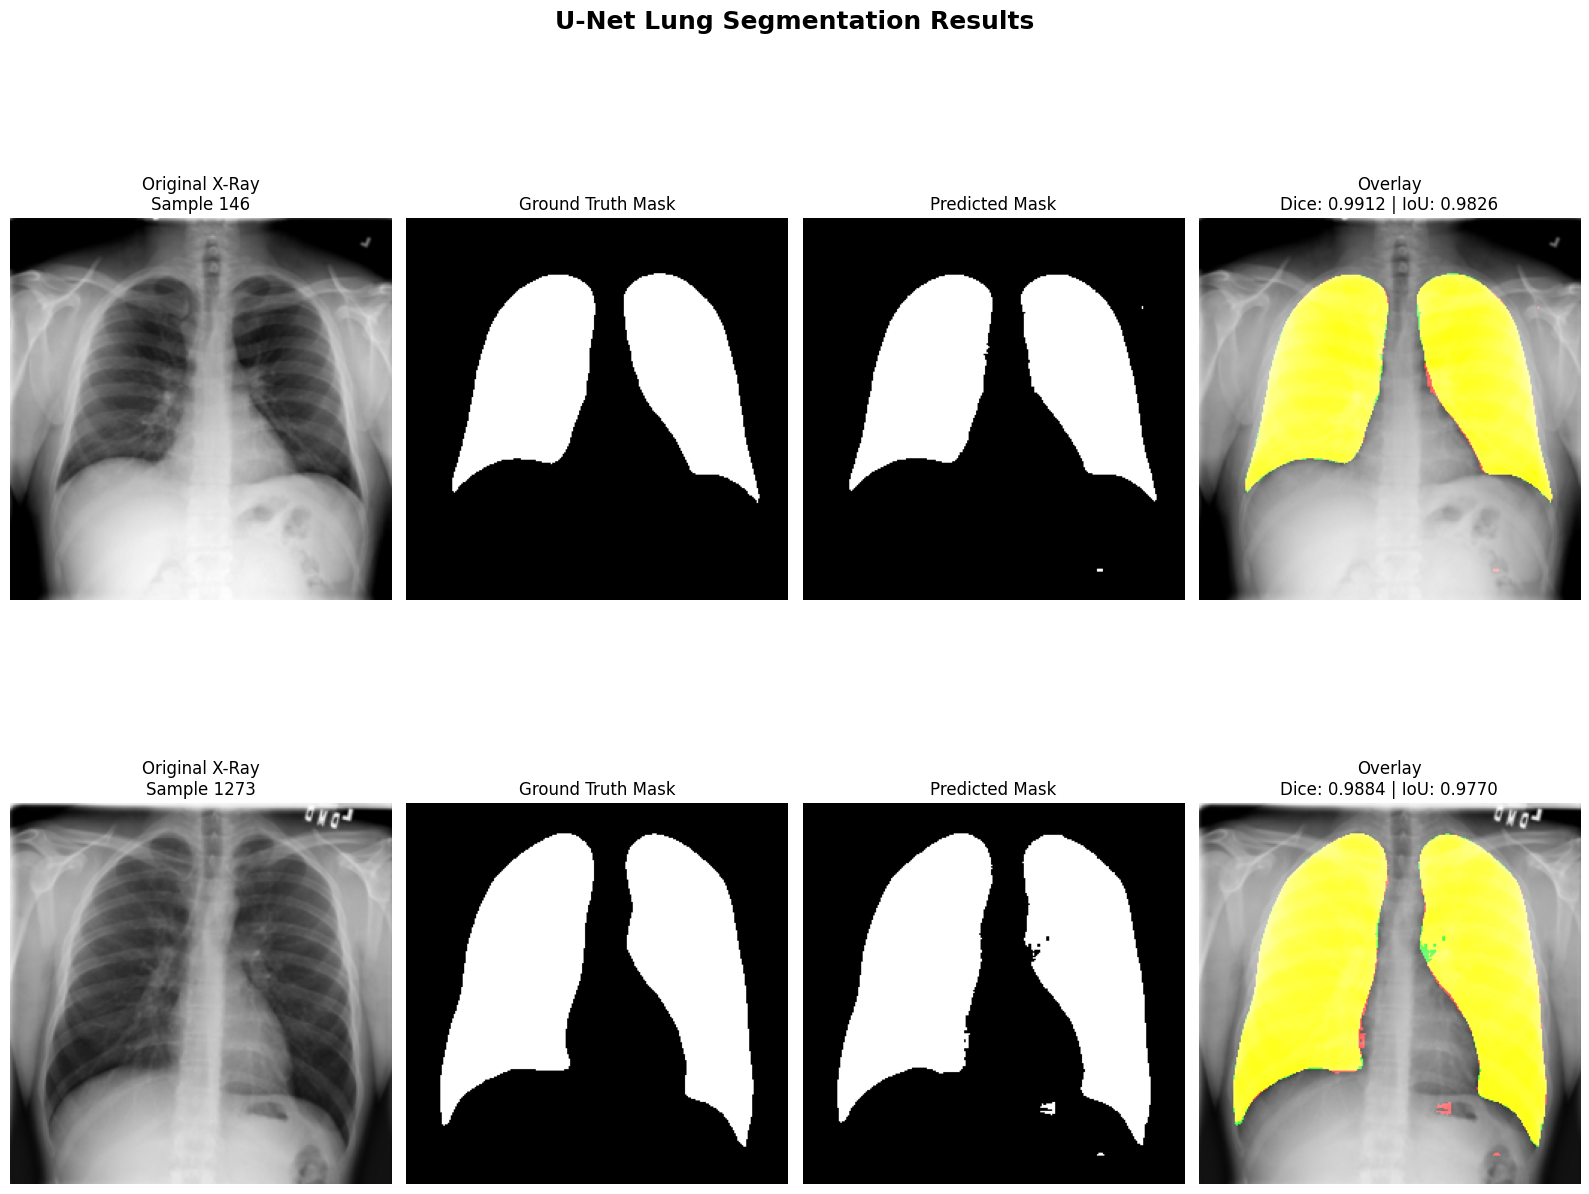

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def visualize_unet_predictions(
    model,
    dataset,
    device,
    num_samples=2,
    seed=42
):

    model.eval()

    rng = np.random.default_rng(seed)

    indices = rng.choice(
        len(dataset),
        size=min(num_samples, len(dataset)),
        replace=False
    )

    fig, axes = plt.subplots(
        len(indices),
        4,
        figsize=(16, 7 * len(indices))
    )

    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    with torch.no_grad():

        for row, idx in enumerate(indices):

            image, true_mask = dataset[idx]

            image_input = image.unsqueeze(0).to(device)

            predicted_mask = model(image_input)

            image_np = (
                image.squeeze()
                .cpu()
                .numpy()
            )

            true_mask_np = (
                true_mask.squeeze()
                .cpu()
                .numpy() > 0.5
            ).astype(np.float32)

            predicted_mask_np = (
                predicted_mask.squeeze()
                .cpu()
                .numpy() > 0.5
            ).astype(np.float32)

            intersection = np.sum(
                predicted_mask_np * true_mask_np
            )

            dice = (
                2 * intersection
            ) / (
                np.sum(predicted_mask_np)
                +
                np.sum(true_mask_np)
                +
                1e-8
            )

            union = (
                np.sum(predicted_mask_np)
                +
                np.sum(true_mask_np)
                -
                intersection
            )

            iou = intersection / (
                union + 1e-8
            )

            overlay = np.stack(
                [
                    image_np,
                    image_np,
                    image_np
                ],
                axis=-1
            )

            overlay[
                true_mask_np > 0.5,
                1
            ] = 1.0

            overlay[
                predicted_mask_np > 0.5,
                0
            ] = 1.0

            axes[row, 0].imshow(
                image_np,
                cmap="gray"
            )

            axes[row, 0].set_title(
                f"Original X-Ray\nSample {idx}"
            )

            axes[row, 0].axis("off")

            axes[row, 1].imshow(
                true_mask_np,
                cmap="gray"
            )

            axes[row, 1].set_title(
                "Ground Truth Mask"
            )

            axes[row, 1].axis("off")

            axes[row, 2].imshow(
                predicted_mask_np,
                cmap="gray"
            )

            axes[row, 2].set_title(
                "Predicted Mask"
            )

            axes[row, 2].axis("off")

            axes[row, 3].imshow(
                overlay
            )

            axes[row, 3].set_title(
                f"Overlay\n"
                f"Dice: {dice:.4f} | "
                f"IoU: {iou:.4f}"
            )

            axes[row, 3].axis("off")

            print(
                f"Sample {idx} | "
                f"Dice: {dice:.4f} | "
                f"IoU: {iou:.4f}"
            )

    plt.suptitle(
        "U-Net Lung Segmentation Results",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


visualize_unet_predictions(
    model=test_model,
    dataset=test_ds,
    device=DEVICE,
    num_samples=2,
    seed=42
)

In [ ]:
import numpy as np
import pandas as pd
import torch
from skimage.measure import label, regionprops


def extract_mask_features(image, mask):

    mask = mask.astype(bool)

    total_pixels = mask.size
    lung_pixels = mask.sum()

    features = {}

    features["lung_area_ratio"] = (
        lung_pixels / total_pixels
    )

    labeled_mask = label(mask)

    regions = regionprops(
        labeled_mask
    )

    features["num_lung_regions"] = len(
        regions
    )

    if lung_pixels > 0:

        features["mean_lung_intensity"] = float(
            image[mask].mean()
        )

    else:

        features["mean_lung_intensity"] = 0.0

    if regions:

        largest_region = max(
            regions,
            key=lambda region: region.area
        )

        features[
            "largest_lung_region_ratio"
        ] = (
            largest_region.area
            / total_pixels
        )

    else:

        features[
            "largest_lung_region_ratio"
        ] = 0.0

    return features


def build_feature_dataset(
    model,
    dataset,
    device
):

    model.eval()

    records = []

    with torch.no_grad():

        for i in range(
            len(dataset)
        ):

            image_tensor, _ = dataset[i]

            x = (
                image_tensor
                .unsqueeze(0)
                .to(device)
            )

            prediction = model(x)

            image_np = (
                image_tensor
                .squeeze()
                .cpu()
                .numpy()
            )

            mask_np = (
                prediction
                .squeeze()
                .cpu()
                .numpy()
                >= 0.5
            ).astype(np.uint8)

            features = extract_mask_features(
                image_np,
                mask_np
            )

            features["image_id"] = i

            records.append(
                features
            )

    columns = [
        "image_id",
        "lung_area_ratio",
        "num_lung_regions",
        "mean_lung_intensity",
        "largest_lung_region_ratio"
    ]

    return pd.DataFrame(
        records,
        columns=columns
    )


feature_model = UNet().to(
    DEVICE
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):

    state_dict = checkpoint[
        "model_state_dict"
    ]

else:

    state_dict = checkpoint


feature_model.load_state_dict(
    state_dict
)

feature_model.eval()


features_df = build_feature_dataset(
    model=feature_model,
    dataset=test_ds,
    device=DEVICE
)


print(
    "U-NET MASK-BASED FEATURE EXTRACTION"
)

print(
    f"\nFeature Dataset Shape: "
    f"{features_df.shape}"
)

print(
    "\nFeature Columns:"
)

print(
    features_df.columns.tolist()
)

print(
    "\nFirst 5 Samples:"
)

display(
    features_df.head()
)

print(
    "\nFeature Statistics:"
)

display(
    features_df.describe()
)

print(
    "\nMissing Values:"
)

display(
    features_df.isnull().sum()
)

U-NET MASK-BASED FEATURE EXTRACTION

Feature Dataset Shape: (1645, 5)

Feature Columns:
['image_id', 'lung_area_ratio', 'num_lung_regions', 'mean_lung_intensity', 'largest_lung_region_ratio']

First 5 Samples:


,image_id,lung_area_ratio,num_lung_regions,mean_lung_intensity,largest_lung_region_ratio
0,0,0.245071,10,0.524098,0.122986
1,1,0.305206,9,0.296827,0.168655
2,2,0.211334,2,0.531489,0.116455
3,3,0.356247,2,0.453845,0.194824
4,4,0.262833,2,0.331222,0.141708



Feature Statistics:


,image_id,lung_area_ratio,num_lung_regions,mean_lung_intensity,largest_lung_region_ratio
count,1645.000000,1645.000000,1645.000000,1645.000000,1645.000000
mean,822.000000,0.230572,11.193921,0.421467,0.125468
std,475.014912,0.063225,9.402824,0.100980,0.034030
min,0.000000,0.054108,2.000000,0.086651,0.027985
25%,411.000000,0.187424,5.000000,0.346487,0.103699
50%,822.000000,0.226730,8.000000,0.420020,0.124054
75%,1233.000000,0.269440,15.000000,0.496303,0.146698
max,1644.000000,0.514389,75.000000,0.737583,0.317520



Missing Values:


,0
image_id,0
lung_area_ratio,0
num_lung_regions,0
mean_lung_intensity,0
largest_lung_region_ratio,0


AUTOMATED LUNG SEGMENTATION ANALYSIS

Processing 4 sample(s)...
Analyzing Sample 1/4 (Index: 721)
Dice: 0.9908 | IoU: 0.9817 | Lung Area: 19.36%
Analyzing Sample 2/4 (Index: 146)
Dice: 0.9912 | IoU: 0.9826 | Lung Area: 24.99%
Analyzing Sample 3/4 (Index: 1076)
Dice: 0.9344 | IoU: 0.8769 | Lung Area: 10.59%
Analyzing Sample 4/4 (Index: 1271)
Dice: 0.9611 | IoU: 0.9251 | Lung Area: 16.63%
GENERATING LUNG ANALYSIS REPORT


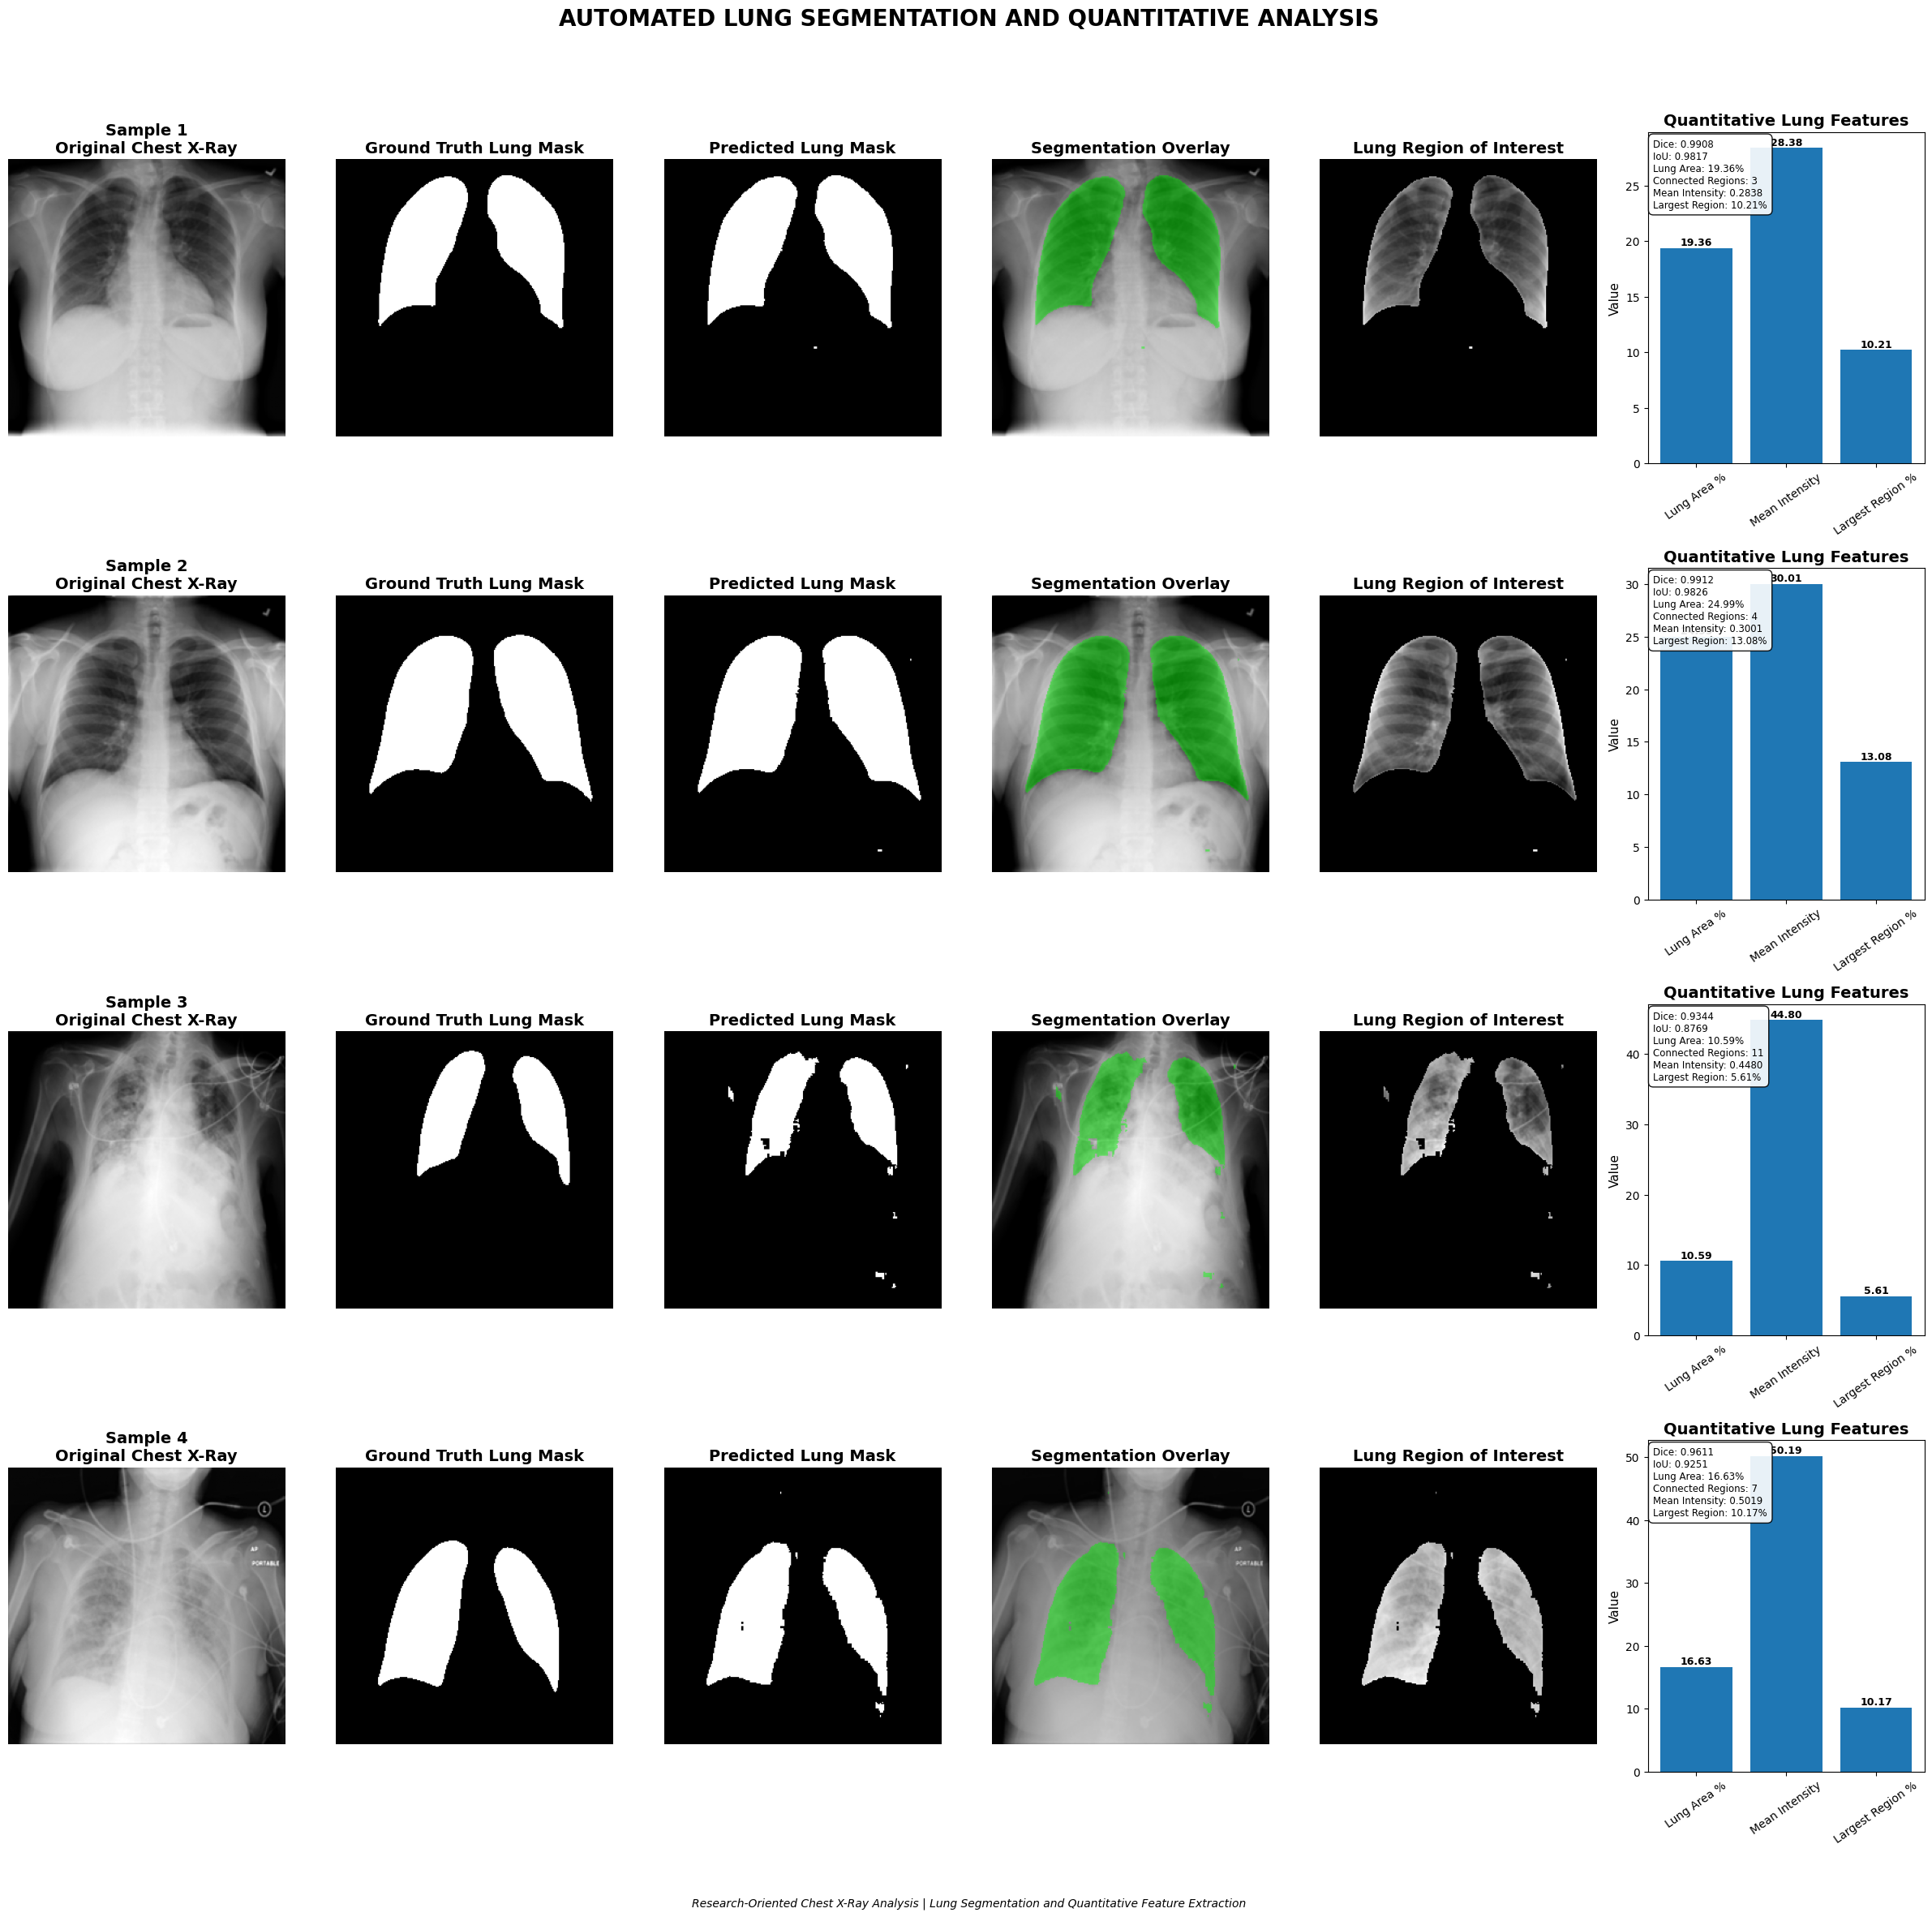

LUNG ANALYSIS REPORT

SAMPLE 1
Index: 721
Dice: 0.9908
IoU: 0.9817
Lung Area: 19.36%
Connected Regions: 3
Mean Lung Intensity: 0.2838
Largest Lung Region: 10.21%

SAMPLE 2
Index: 146
Dice: 0.9912
IoU: 0.9826
Lung Area: 24.99%
Connected Regions: 4
Mean Lung Intensity: 0.3001
Largest Lung Region: 13.08%

SAMPLE 3
Index: 1076
Dice: 0.9344
IoU: 0.8769
Lung Area: 10.59%
Connected Regions: 11
Mean Lung Intensity: 0.4480
Largest Lung Region: 5.61%

SAMPLE 4
Index: 1271
Dice: 0.9611
IoU: 0.9251
Lung Area: 16.63%
Connected Regions: 7
Mean Lung Intensity: 0.5019
Largest Lung Region: 10.17%

Report saved to: lung_analysis_report.png

ANALYSIS COMPLETE


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops


SEED = 42


class Config:

    FIG_WIDTH = 24
    FIG_HEIGHT_PER_SAMPLE = 6
    FONT_SIZE_TITLE = 14
    FONT_SIZE_LABEL = 11


def calculate_dice(pred, target, smooth=1.0):

    pred = pred.astype(np.uint8)
    target = target.astype(np.uint8)

    intersection = np.sum(
        pred * target
    )

    return (
        2.0 * intersection + smooth
    ) / (
        np.sum(pred)
        +
        np.sum(target)
        +
        smooth
    )


def calculate_iou(pred, target, smooth=1.0):

    pred = pred.astype(np.uint8)
    target = target.astype(np.uint8)

    intersection = np.sum(
        pred * target
    )

    union = (
        np.sum(pred)
        +
        np.sum(target)
        -
        intersection
    )

    return (
        intersection + smooth
    ) / (
        union + smooth
    )


def extract_lung_features(image, mask):

    mask = mask.astype(bool)

    total_pixels = mask.size
    lung_pixels = mask.sum()

    lung_area_ratio = (
        lung_pixels / total_pixels
        if total_pixels > 0
        else 0.0
    )

    labeled_mask = label(mask)

    regions = regionprops(
        labeled_mask
    )

    num_regions = len(regions)

    if lung_pixels > 0:

        mean_intensity = float(
            image[mask].mean()
        )

    else:

        mean_intensity = 0.0

    if regions:

        largest_region = max(
            regions,
            key=lambda region: region.area
        )

        largest_region_ratio = (
            largest_region.area
            / total_pixels
        )

    else:

        largest_region_ratio = 0.0

    return {
        "lung_area_ratio": lung_area_ratio,
        "lung_area_percentage": (
            lung_area_ratio * 100
        ),
        "num_lung_regions": num_regions,
        "mean_lung_intensity": mean_intensity,
        "largest_lung_region_ratio": (
            largest_region_ratio
        ),
        "largest_lung_region_percentage": (
            largest_region_ratio * 100
        )
    }


class LungAnalysisSystem:

    def __init__(self, model, device):

        self.model = model
        self.device = device
        self.config = Config()

        self.model.to(
            self.device
        )

        self.model.eval()

    def predict_lung_mask(
        self,
        image_tensor
    ):

        x = (
            image_tensor
            .unsqueeze(0)
            .to(self.device)
        )

        with torch.no_grad():

            prediction = self.model(x)

        prediction = (
            prediction
            .squeeze()
            .cpu()
            .numpy()
        )

        predicted_mask = (
            prediction >= 0.5
        ).astype(np.uint8)

        return predicted_mask

    def analyze_sample(
        self,
        dataset,
        index
    ):

        image_tensor, true_mask_tensor = (
            dataset[index]
        )

        image = (
            image_tensor
            .squeeze()
            .cpu()
            .numpy()
        )

        true_mask = (
            true_mask_tensor
            .squeeze()
            .cpu()
            .numpy()
        )

        true_mask = (
            true_mask >= 0.5
        ).astype(np.uint8)

        predicted_mask = (
            self.predict_lung_mask(
                image_tensor
            )
        )

        dice = calculate_dice(
            predicted_mask,
            true_mask
        )

        iou = calculate_iou(
            predicted_mask,
            true_mask
        )

        features = extract_lung_features(
            image,
            predicted_mask
        )

        return {
            "index": index,
            "image": image,
            "true_mask": true_mask,
            "predicted_mask": predicted_mask,
            "dice": dice,
            "iou": iou,
            "features": features
        }


class ProfessionalLungReport:

    def __init__(self):

        self.config = Config()

    def create_report(
        self,
        results_list,
        save_path="lung_analysis_report.png"
    ):

        num_samples = len(
            results_list
        )

        fig, axes = plt.subplots(
            num_samples,
            6,
            figsize=(
                self.config.FIG_WIDTH,
                self.config.FIG_HEIGHT_PER_SAMPLE
                * num_samples
            )
        )

        if num_samples == 1:

            axes = np.expand_dims(
                axes,
                axis=0
            )

        fig.suptitle(
            "AUTOMATED LUNG SEGMENTATION AND QUANTITATIVE ANALYSIS",
            fontsize=20,
            fontweight="bold",
            y=0.99
        )

        for row_index, results in enumerate(
            results_list
        ):

            image = results["image"]

            true_mask = results[
                "true_mask"
            ]

            predicted_mask = results[
                "predicted_mask"
            ]

            dice = results["dice"]
            iou = results["iou"]

            features = results[
                "features"
            ]

            lung_roi = (
                image * predicted_mask
            )

            overlay = np.stack(
                [
                    image,
                    image,
                    image
                ],
                axis=-1
            )

            overlay[
                predicted_mask == 1
            ] = (
                0.55
                * overlay[
                    predicted_mask == 1
                ]
                +
                0.45
                * np.array(
                    [0.0, 1.0, 0.0]
                )
            )

            ax1 = axes[
                row_index, 0
            ]

            ax2 = axes[
                row_index, 1
            ]

            ax3 = axes[
                row_index, 2
            ]

            ax4 = axes[
                row_index, 3
            ]

            ax5 = axes[
                row_index, 4
            ]

            ax6 = axes[
                row_index, 5
            ]

            ax1.imshow(
                image,
                cmap="gray"
            )

            ax1.set_title(
                f"Sample {row_index + 1}\n"
                "Original Chest X-Ray",
                fontsize=self.config.FONT_SIZE_TITLE,
                fontweight="bold"
            )

            ax1.axis("off")

            ax2.imshow(
                true_mask,
                cmap="gray"
            )

            ax2.set_title(
                "Ground Truth Lung Mask",
                fontsize=self.config.FONT_SIZE_TITLE,
                fontweight="bold"
            )

            ax2.axis("off")

            ax3.imshow(
                predicted_mask,
                cmap="gray"
            )

            ax3.set_title(
                "Predicted Lung Mask",
                fontsize=self.config.FONT_SIZE_TITLE,
                fontweight="bold"
            )

            ax3.axis("off")

            ax4.imshow(
                overlay
            )

            ax4.set_title(
                "Segmentation Overlay",
                fontsize=self.config.FONT_SIZE_TITLE,
                fontweight="bold"
            )

            ax4.axis("off")

            ax5.imshow(
                lung_roi,
                cmap="gray"
            )

            ax5.set_title(
                "Lung Region of Interest",
                fontsize=self.config.FONT_SIZE_TITLE,
                fontweight="bold"
            )

            ax5.axis("off")

            categories = [
                "Lung Area %",
                "Mean Intensity",
                "Largest Region %"
            ]

            values = [
                features[
                    "lung_area_percentage"
                ],
                features[
                    "mean_lung_intensity"
                ] * 100,
                features[
                    "largest_lung_region_percentage"
                ]
            ]

            bars = ax6.bar(
                categories,
                values
            )

            ax6.set_title(
                "Quantitative Lung Features",
                fontsize=self.config.FONT_SIZE_TITLE,
                fontweight="bold"
            )

            ax6.set_ylabel(
                "Value",
                fontsize=self.config.FONT_SIZE_LABEL
            )

            ax6.tick_params(
                axis="x",
                rotation=35
            )

            for bar, value in zip(
                bars,
                values
            ):

                ax6.text(
                    bar.get_x()
                    + bar.get_width() / 2,
                    bar.get_height(),
                    f"{value:.2f}",
                    ha="center",
                    va="bottom",
                    fontsize=9,
                    fontweight="bold"
                )

            info_text = (
                f"Dice: {dice:.4f}\n"
                f"IoU: {iou:.4f}\n"
                f"Lung Area: "
                f"{features['lung_area_percentage']:.2f}%\n"
                f"Connected Regions: "
                f"{features['num_lung_regions']}\n"
                f"Mean Intensity: "
                f"{features['mean_lung_intensity']:.4f}\n"
                f"Largest Region: "
                f"{features['largest_lung_region_percentage']:.2f}%"
            )

            ax6.text(
                0.02,
                0.98,
                info_text,
                transform=ax6.transAxes,
                fontsize=8.5,
                verticalalignment="top",
                bbox=dict(
                    boxstyle="round,pad=0.5",
                    facecolor="white",
                    edgecolor="black",
                    alpha=0.9
                )
            )

        plt.tight_layout(
            rect=[
                0,
                0.04,
                1,
                0.96
            ]
        )

        fig.text(
            0.5,
            0.015,
            "Research-Oriented Chest X-Ray Analysis | "
            "Lung Segmentation and Quantitative Feature Extraction",
            ha="center",
            fontsize=10,
            style="italic"
        )

        plt.savefig(
            save_path,
            dpi=250,
            bbox_inches="tight",
            facecolor="white"
        )

        plt.show()

        print(
            "LUNG ANALYSIS REPORT"
        )

        for i, results in enumerate(
            results_list
        ):

            features = results[
                "features"
            ]

            print(
                f"\nSAMPLE {i + 1}"
            )

            print(
                f"Index: "
                f"{results['index']}"
            )

            print(
                f"Dice: "
                f"{results['dice']:.4f}"
            )

            print(
                f"IoU: "
                f"{results['iou']:.4f}"
            )

            print(
                f"Lung Area: "
                f"{features['lung_area_percentage']:.2f}%"
            )

            print(
                f"Connected Regions: "
                f"{features['num_lung_regions']}"
            )

            print(
                f"Mean Lung Intensity: "
                f"{features['mean_lung_intensity']:.4f}"
            )

            print(
                f"Largest Lung Region: "
                f"{features['largest_lung_region_percentage']:.2f}%"
            )

        print()

        print(
            f"Report saved to: {save_path}"
        )


def run_lung_analysis(
    model,
    dataset,
    device,
    num_samples=4,
    save_report=True,
    report_name="lung_analysis_report.png"
):

    print(
        "AUTOMATED LUNG SEGMENTATION ANALYSIS"
    )

    if num_samples > len(dataset):

        num_samples = len(dataset)

    rng = np.random.default_rng(
        SEED
    )

    indices = rng.choice(
        len(dataset),
        num_samples,
        replace=False
    )

    analyzer = LungAnalysisSystem(
        model,
        device
    )

    results = []

    print(
        f"\nProcessing "
        f"{num_samples} sample(s)..."
    )

    for i, index in enumerate(
        indices
    ):

        print(
            f"Analyzing Sample "
            f"{i + 1}/{num_samples} "
            f"(Index: {index})"
        )

        try:

            result = analyzer.analyze_sample(
                dataset,
                index
            )

            results.append(
                result
            )

            print(
                f"Dice: "
                f"{result['dice']:.4f} | "
                f"IoU: "
                f"{result['iou']:.4f} | "
                f"Lung Area: "
                f"{result['features']['lung_area_percentage']:.2f}%"
            )

        except Exception as e:

            print(
                f"Error processing sample "
                f"{index}: {e}"
            )

    if results:

        print(
            "GENERATING LUNG ANALYSIS REPORT"
        )

        if save_report:

            reporter = ProfessionalLungReport()

            reporter.create_report(
                results,
                save_path=report_name
            )

        print(
            "\nANALYSIS COMPLETE"
        )

    else:

        print(
            "\nNo valid samples were processed."
        )

    return results


report_model = UNet().to(
    DEVICE
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):

    state_dict = checkpoint[
        "model_state_dict"
    ]

else:

    state_dict = checkpoint

report_model.load_state_dict(
    state_dict
)

report_model.eval()

results = run_lung_analysis(
    model=report_model,
    dataset=test_ds,
    device=DEVICE,
    num_samples=4,
    save_report=True,
    report_name="lung_analysis_report.png"
)

RESNET18 CLASSIFICATION DATASET

Total Images: 10961
Train: 7672
Validation: 1644
Test: 1645

Train Distribution: Counter({np.int64(0): 2531, np.int64(1): 2100, np.int64(2): 2100, np.int64(3): 941})
Validation Distribution: Counter({np.int64(0): 542, np.int64(1): 450, np.int64(2): 450, np.int64(3): 202})
Test Distribution: Counter({np.int64(0): 543, np.int64(2): 450, np.int64(1): 450, np.int64(3): 202})

Sample shape: torch.Size([3, 224, 224])
Sample label: 1
Batch shape: torch.Size([32, 3, 224, 224])

Class Weights: [0.75780326 0.91333336 0.91333336 2.0382571 ]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 145MB/s]



STARTING RESNET18 TRAINING
Epoch 1/15 | Train Loss: 0.8212 | Train Acc: 0.7517 | Train F1: 0.7503 | Val Loss: 0.6903 | Val Acc: 0.8437 | Val F1: 0.8435 | LR: 1.00e-04
Best ResNet model saved.
Epoch 2/15 | Train Loss: 0.6857 | Train Acc: 0.8360 | Train F1: 0.8356 | Val Loss: 0.6186 | Val Acc: 0.8777 | Val F1: 0.8776 | LR: 1.00e-04
Best ResNet model saved.
Epoch 3/15 | Train Loss: 0.6325 | Train Acc: 0.8730 | Train F1: 0.8729 | Val Loss: 0.7248 | Val Acc: 0.8090 | Val F1: 0.8049 | LR: 1.00e-04
Epoch 4/15 | Train Loss: 0.6076 | Train Acc: 0.8848 | Train F1: 0.8845 | Val Loss: 0.5949 | Val Acc: 0.8820 | Val F1: 0.8816 | LR: 1.00e-04
Best ResNet model saved.
Epoch 5/15 | Train Loss: 0.5840 | Train Acc: 0.9019 | Train F1: 0.9018 | Val Loss: 0.6097 | Val Acc: 0.8869 | Val F1: 0.8869 | LR: 1.00e-04
Best ResNet model saved.
Epoch 6/15 | Train Loss: 0.5652 | Train Acc: 0.9102 | Train F1: 0.9101 | Val Loss: 0.5722 | Val Acc: 0.9045 | Val F1: 0.9050 | LR: 1.00e-04
Best ResNet model saved.
Epoch 7

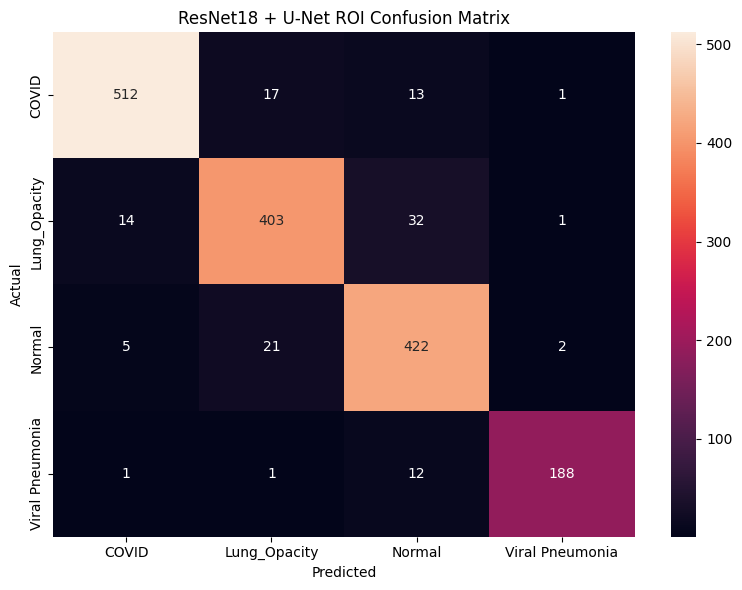

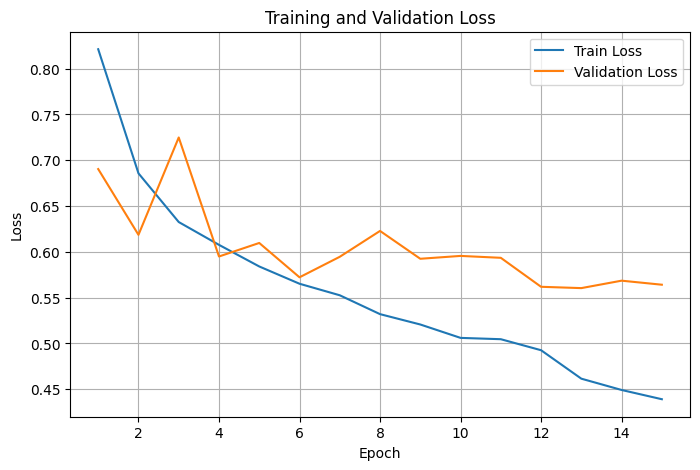

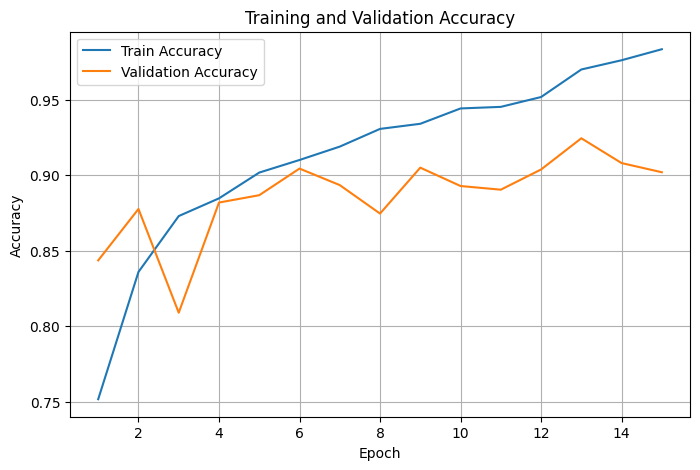

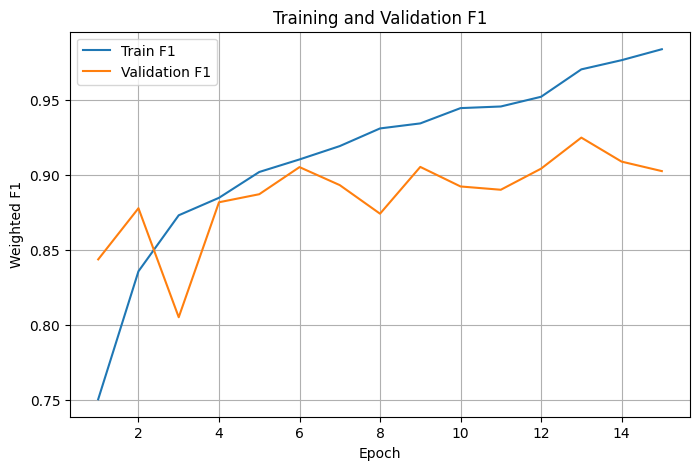


Best Validation F1: 0.9246723545118932
Saved model: /content/best_resnet18_unet_roi.pth


In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from collections import Counter


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 32
EPOCHS = 15
LR = 1e-4

IMAGE_SIZE = 256
RESNET_SIZE = 224

BEST_UNET_PATH = "/content/best_unet.pth"
BEST_RESNET_PATH = "/content/best_resnet18_unet_roi.pth"


classes = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

class_to_idx = {
    cls: i
    for i, cls in enumerate(classes)
}


classification_labels = list(labels)

assert len(image_paths) == len(classification_labels)

train_indices = list(train_ds.indices)
val_indices = list(val_ds.indices)
test_indices = list(test_ds.indices)


train_paths = [
    image_paths[i]
    for i in train_indices
]

train_labels = [
    classification_labels[i]
    for i in train_indices
]


val_paths = [
    image_paths[i]
    for i in val_indices
]

val_labels = [
    classification_labels[i]
    for i in val_indices
]


test_paths = [
    image_paths[i]
    for i in test_indices
]

test_labels = [
    classification_labels[i]
    for i in test_indices
]


print("=" * 60)
print("RESNET18 CLASSIFICATION DATASET")
print("=" * 60)

print(
    f"\nTotal Images: {len(image_paths)}"
)

print(
    f"Train: {len(train_paths)}"
)

print(
    f"Validation: {len(val_paths)}"
)

print(
    f"Test: {len(test_paths)}"
)

print(
    "\nTrain Distribution:",
    Counter(train_labels)
)

print(
    "Validation Distribution:",
    Counter(val_labels)
)

print(
    "Test Distribution:",
    Counter(test_labels)
)


class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.enc1 = nn.Sequential(
            nn.Conv2d(1, 64, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, 1, 1),
            nn.ReLU()
        )

        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, 1, 1),
            nn.ReLU()
        )

        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(128, 256, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, 1, 1),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            2,
            2
        )

        self.dec2 = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1),
            nn.ReLU()
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            2,
            2
        )

        self.dec1 = nn.Sequential(
            nn.Conv2d(128, 64, 3, 1, 1),
            nn.ReLU()
        )

        self.out = nn.Conv2d(
            64,
            1,
            1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool1(e1)
        )

        b = self.bottleneck(
            self.pool2(e2)
        )

        d2 = self.dec2(
            torch.cat(
                [
                    self.up2(b),
                    e2
                ],
                dim=1
            )
        )

        d1 = self.dec1(
            torch.cat(
                [
                    self.up1(d2),
                    e1
                ],
                dim=1
            )
        )

        return torch.sigmoid(
            self.out(d1)
        )


unet_model = UNet().to(
    DEVICE
)

unet_checkpoint = torch.load(
    BEST_UNET_PATH,
    map_location=DEVICE,
    weights_only=False
)

if (
    isinstance(unet_checkpoint, dict)
    and "model_state_dict" in unet_checkpoint
):

    unet_state_dict = (
        unet_checkpoint[
            "model_state_dict"
        ]
    )

else:

    unet_state_dict = unet_checkpoint


unet_model.load_state_dict(
    unet_state_dict
)

unet_model.eval()


for parameter in unet_model.parameters():
    parameter.requires_grad = False


class UNetROIDataset(Dataset):

    def __init__(
        self,
        image_paths,
        labels,
        train=False
    ):

        self.image_paths = image_paths
        self.labels = labels
        self.train = train

        self.train_transform = transforms.Compose([

            transforms.ToPILImage(),

            transforms.Resize(
                (
                    RESNET_SIZE,
                    RESNET_SIZE
                )
            ),

            transforms.RandomHorizontalFlip(
                p=0.5
            ),

            transforms.RandomRotation(
                7
            ),

            transforms.ToTensor(),

            transforms.Normalize(
                mean=[
                    0.485,
                    0.456,
                    0.406
                ],
                std=[
                    0.229,
                    0.224,
                    0.225
                ]
            )
        ])

        self.test_transform = transforms.Compose([

            transforms.ToPILImage(),

            transforms.Resize(
                (
                    RESNET_SIZE,
                    RESNET_SIZE
                )
            ),

            transforms.ToTensor(),

            transforms.Normalize(
                mean=[
                    0.485,
                    0.456,
                    0.406
                ],
                std=[
                    0.229,
                    0.224,
                    0.225
                ]
            )
        ])

    def __len__(self):

        return len(
            self.image_paths
        )

    def __getitem__(self, idx):

        image = Image.open(
            self.image_paths[idx]
        ).convert("L")

        image = image.resize(
            (
                IMAGE_SIZE,
                IMAGE_SIZE
            )
        )

        image = np.array(
            image,
            dtype=np.float32
        ) / 255.0

        image = torch.from_numpy(
            image
        ).unsqueeze(0)

        with torch.no_grad():

            predicted_mask = unet_model(
                image.unsqueeze(0).to(
                    DEVICE
                )
            )

        predicted_mask = (
            predicted_mask
            .squeeze(0)
            .squeeze(0)
            .cpu()
        )

        predicted_mask = (
            predicted_mask >= 0.5
        ).float()

        roi = (
            image
            * predicted_mask.unsqueeze(0)
        )

        roi = roi.clamp(
            0,
            1
        )

        roi = roi.repeat(
            3,
            1,
            1
        )

        if self.train:

            roi = self.train_transform(
                roi
            )

        else:

            roi = self.test_transform(
                roi
            )

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return roi, label


train_dataset = UNetROIDataset(
    train_paths,
    train_labels,
    train=True
)

val_dataset = UNetROIDataset(
    val_paths,
    val_labels,
    train=False
)

test_dataset = UNetROIDataset(
    test_paths,
    test_labels,
    train=False
)


sample_image, sample_label = (
    train_dataset[0]
)

print(
    "\nSample shape:",
    sample_image.shape
)

print(
    "Sample label:",
    sample_label.item()
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


batch_images, batch_labels = next(
    iter(train_loader)
)

print(
    "Batch shape:",
    batch_images.shape
)


train_counts = Counter(
    train_labels
)


class_weights = torch.tensor(
    [
        len(train_labels)
        / (
            len(classes)
            * train_counts[i]
        )
        for i in range(
            len(classes)
        )
    ],
    dtype=torch.float32
).to(DEVICE)


print(
    "\nClass Weights:",
    class_weights.cpu().numpy()
)


resnet = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)


resnet.fc = nn.Sequential(

    nn.Linear(
        resnet.fc.in_features,
        256
    ),

    nn.ReLU(),

    nn.Dropout(
        0.5
    ),

    nn.Linear(
        256,
        len(classes)
    )
)


resnet = resnet.to(
    DEVICE
)


criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.1
)


optimizer = torch.optim.AdamW(
    resnet.parameters(),
    lr=LR,
    weight_decay=5e-4
)


scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )
)


best_val_f1 = -np.inf
patience = 4
early_stop_counter = 0


history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": []
}


print(
    "\n" + "=" * 60
)

print(
    "STARTING RESNET18 TRAINING"
)

print(
    "=" * 60
)


for epoch in range(EPOCHS):

    resnet.train()

    running_loss = 0.0

    train_true = []
    train_pred = []


    for images, labels_batch in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels_batch = labels_batch.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = resnet(
            images
        )

        loss = criterion(
            outputs,
            labels_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        train_true.extend(
            labels_batch
            .cpu()
            .numpy()
        )

        train_pred.extend(
            predictions
            .cpu()
            .numpy()
        )


    train_loss = (
        running_loss
        / len(train_loader.dataset)
    )

    train_acc = accuracy_score(
        train_true,
        train_pred
    )

    train_f1 = f1_score(
        train_true,
        train_pred,
        average="weighted",
        zero_division=0
    )


    resnet.eval()

    val_loss_total = 0.0

    val_true = []
    val_pred = []


    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels_batch = labels_batch.to(
                DEVICE,
                non_blocking=True
            )

            outputs = resnet(
                images
            )

            loss = criterion(
                outputs,
                labels_batch
            )

            val_loss_total += (
                loss.item()
                * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_true.extend(
                labels_batch
                .cpu()
                .numpy()
            )

            val_pred.extend(
                predictions
                .cpu()
                .numpy()
            )


    val_loss = (
        val_loss_total
        / len(val_loader.dataset)
    )

    val_acc = accuracy_score(
        val_true,
        val_pred
    )

    val_f1 = f1_score(
        val_true,
        val_pred,
        average="weighted",
        zero_division=0
    )


    scheduler.step(
        val_f1
    )


    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_acc"].append(
        val_acc
    )

    history["train_f1"].append(
        train_f1
    )

    history["val_f1"].append(
        val_f1
    )


    current_lr = optimizer.param_groups[
        0
    ]["lr"]


    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"LR: {current_lr:.2e}"
    )


    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        early_stop_counter = 0

        torch.save(
            {
                "model_state_dict":
                    resnet.state_dict(),

                "classes":
                    classes,

                "class_to_idx":
                    class_to_idx,

                "best_val_f1":
                    best_val_f1
            },
            BEST_RESNET_PATH
        )

        print(
            "Best ResNet model saved."
        )

    else:

        early_stop_counter += 1

        if (
            early_stop_counter
            >= patience
        ):

            print(
                "Early stopping."
            )

            break


checkpoint = torch.load(
    BEST_RESNET_PATH,
    map_location=DEVICE,
    weights_only=False
)


resnet.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

resnet.eval()


test_true = []
test_pred = []
test_probs = []


with torch.no_grad():

    for images, labels_batch in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        outputs = resnet(
            images
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        test_true.extend(
            labels_batch.numpy()
        )

        test_pred.extend(
            predictions
            .cpu()
            .numpy()
        )

        test_probs.extend(
            probabilities
            .cpu()
            .numpy()
        )


test_accuracy = accuracy_score(
    test_true,
    test_pred
)

test_precision = precision_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)


print(
    "\n" + "=" * 60
)

print(
    "FINAL RESNET18 TEST RESULTS"
)

print(
    "=" * 60
)

print(
    f"Test Samples: {len(test_dataset)}"
)

print(
    f"Accuracy    : {test_accuracy:.4f}"
)

print(
    f"Precision   : {test_precision:.4f}"
)

print(
    f"Recall      : {test_recall:.4f}"
)

print(
    f"F1 Score    : {test_f1:.4f}"
)


print(
    "\nClassification Report:\n"
)


print(
    classification_report(
        test_true,
        test_pred,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


cm = confusion_matrix(
    test_true,
    test_pred
)


plt.figure(
    figsize=(8, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "ResNet18 + U-Net ROI Confusion Matrix"
)

plt.tight_layout()

plt.show()


epochs_range = range(
    1,
    len(history["train_loss"]) + 1
)


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.grid()

plt.show()


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.grid()

plt.show()


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_f1"],
    label="Train F1"
)

plt.plot(
    epochs_range,
    history["val_f1"],
    label="Validation F1"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Weighted F1"
)

plt.title(
    "Training and Validation F1"

)

plt.legend()

plt.grid()

plt.show()


print(
    "\nBest Validation F1:",
    checkpoint["best_val_f1"]
)

print(
    "Saved model:",
    BEST_RESNET_PATH
)

RESNET34 CLASSIFICATION DATASET

Total Images: 10961
Train: 7672
Validation: 1644
Test: 1645

Train Distribution: Counter({np.int64(0): 2531, np.int64(1): 2100, np.int64(2): 2100, np.int64(3): 941})
Validation Distribution: Counter({np.int64(0): 542, np.int64(1): 450, np.int64(2): 450, np.int64(3): 202})
Test Distribution: Counter({np.int64(0): 543, np.int64(2): 450, np.int64(1): 450, np.int64(3): 202})

Sample shape: torch.Size([3, 224, 224])
Sample label: 1
Batch shape: torch.Size([32, 3, 224, 224])

Class Weights: [0.75780326 0.91333336 0.91333336 2.0382571 ]
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 172MB/s]



STARTING RESNET34 TRAINING
Epoch 1/15 | Train Loss: 0.8166 | Train Acc: 0.7482 | Train F1: 0.7466 | Val Loss: 0.6596 | Val Acc: 0.8358 | Val F1: 0.8347 | LR: 1.00e-04
Best ResNet model saved.
Epoch 2/15 | Train Loss: 0.6785 | Train Acc: 0.8385 | Train F1: 0.8381 | Val Loss: 0.6934 | Val Acc: 0.8236 | Val F1: 0.8161 | LR: 1.00e-04
Epoch 3/15 | Train Loss: 0.6287 | Train Acc: 0.8715 | Train F1: 0.8713 | Val Loss: 0.6612 | Val Acc: 0.8400 | Val F1: 0.8379 | LR: 1.00e-04
Best ResNet model saved.
Epoch 4/15 | Train Loss: 0.6069 | Train Acc: 0.8869 | Train F1: 0.8868 | Val Loss: 0.5789 | Val Acc: 0.8936 | Val F1: 0.8928 | LR: 1.00e-04
Best ResNet model saved.
Epoch 5/15 | Train Loss: 0.5861 | Train Acc: 0.8949 | Train F1: 0.8949 | Val Loss: 0.5717 | Val Acc: 0.8990 | Val F1: 0.8987 | LR: 1.00e-04
Best ResNet model saved.
Epoch 6/15 | Train Loss: 0.5653 | Train Acc: 0.9090 | Train F1: 0.9089 | Val Loss: 0.5872 | Val Acc: 0.8911 | Val F1: 0.8906 | LR: 1.00e-04
Epoch 7/15 | Train Loss: 0.5504 

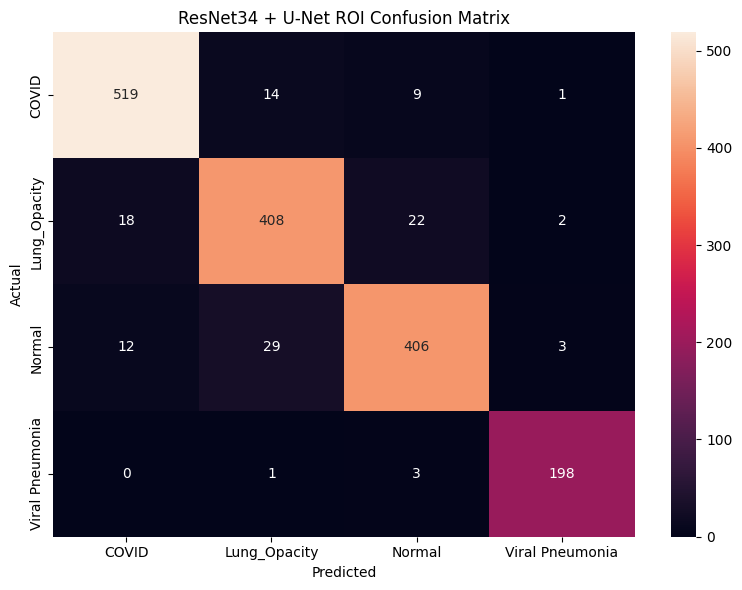

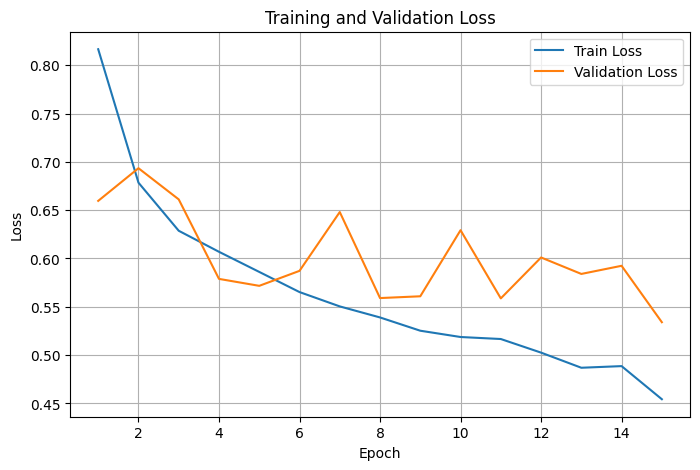

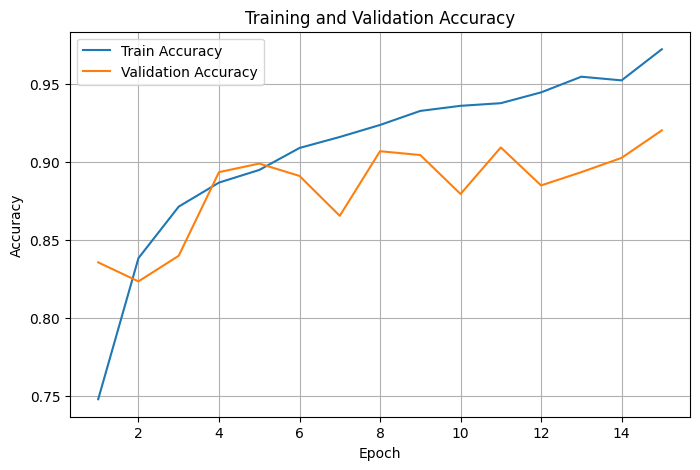

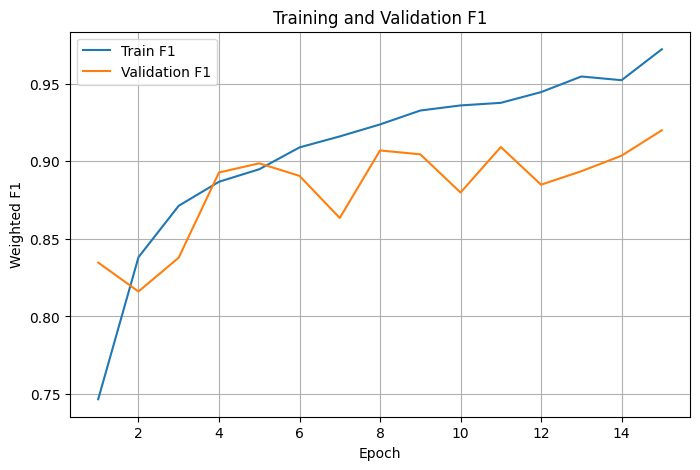


Best Validation F1: 0.9200015599700295
Saved model: /content/best_resnet34_unet_roi.pth


In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from collections import Counter


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 32
EPOCHS = 15
LR = 1e-4

IMAGE_SIZE = 256
RESNET_SIZE = 224

BEST_UNET_PATH = "/content/best_unet.pth"
BEST_RESNET_PATH = "/content/best_resnet34_unet_roi.pth"


classes = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

class_to_idx = {
    cls: i
    for i, cls in enumerate(classes)
}


classification_labels = list(labels)

assert len(image_paths) == len(classification_labels)

train_indices = list(train_ds.indices)
val_indices = list(val_ds.indices)
test_indices = list(test_ds.indices)


train_paths = [
    image_paths[i]
    for i in train_indices
]

train_labels = [
    classification_labels[i]
    for i in train_indices
]


val_paths = [
    image_paths[i]
    for i in val_indices
]

val_labels = [
    classification_labels[i]
    for i in val_indices
]


test_paths = [
    image_paths[i]
    for i in test_indices
]

test_labels = [
    classification_labels[i]
    for i in test_indices
]


print("=" * 60)
print("RESNET34 CLASSIFICATION DATASET")
print("=" * 60)

print(
    f"\nTotal Images: {len(image_paths)}"
)

print(
    f"Train: {len(train_paths)}"
)

print(
    f"Validation: {len(val_paths)}"
)

print(
    f"Test: {len(test_paths)}"
)

print(
    "\nTrain Distribution:",
    Counter(train_labels)
)

print(
    "Validation Distribution:",
    Counter(val_labels)
)

print(
    "Test Distribution:",
    Counter(test_labels)
)


class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.enc1 = nn.Sequential(
            nn.Conv2d(1, 64, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, 1, 1),
            nn.ReLU()
        )

        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, 1, 1),
            nn.ReLU()
        )

        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(128, 256, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, 1, 1),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            2,
            2
        )

        self.dec2 = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1),
            nn.ReLU()
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            2,
            2
        )

        self.dec1 = nn.Sequential(
            nn.Conv2d(128, 64, 3, 1, 1),
            nn.ReLU()
        )

        self.out = nn.Conv2d(
            64,
            1,
            1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool1(e1)
        )

        b = self.bottleneck(
            self.pool2(e2)
        )

        d2 = self.dec2(
            torch.cat(
                [
                    self.up2(b),
                    e2
                ],
                dim=1
            )
        )

        d1 = self.dec1(
            torch.cat(
                [
                    self.up1(d2),
                    e1
                ],
                dim=1
            )
        )

        return torch.sigmoid(
            self.out(d1)
        )


unet_model = UNet().to(DEVICE)

unet_checkpoint = torch.load(
    BEST_UNET_PATH,
    map_location=DEVICE,
    weights_only=False
)

if (
    isinstance(unet_checkpoint, dict)
    and "model_state_dict" in unet_checkpoint
):

    unet_state_dict = (
        unet_checkpoint["model_state_dict"]
    )

else:

    unet_state_dict = unet_checkpoint


unet_model.load_state_dict(
    unet_state_dict
)

unet_model.eval()


for parameter in unet_model.parameters():
    parameter.requires_grad = False


class UNetROIDataset(Dataset):

    def __init__(
        self,
        image_paths,
        labels,
        train=False
    ):

        self.image_paths = image_paths
        self.labels = labels
        self.train = train

        self.train_transform = transforms.Compose([

            transforms.ToPILImage(),

            transforms.Resize(
                (
                    RESNET_SIZE,
                    RESNET_SIZE
                )
            ),

            transforms.RandomHorizontalFlip(
                p=0.5
            ),

            transforms.RandomRotation(
                7
            ),

            transforms.ToTensor(),

            transforms.Normalize(
                mean=[
                    0.485,
                    0.456,
                    0.406
                ],
                std=[
                    0.229,
                    0.224,
                    0.225
                ]
            )
        ])

        self.test_transform = transforms.Compose([

            transforms.ToPILImage(),

            transforms.Resize(
                (
                    RESNET_SIZE,
                    RESNET_SIZE
                )
            ),

            transforms.ToTensor(),

            transforms.Normalize(
                mean=[
                    0.485,
                    0.456,
                    0.406
                ],
                std=[
                    0.229,
                    0.224,
                    0.225
                ]
            )
        ])

    def __len__(self):

        return len(
            self.image_paths
        )

    def __getitem__(self, idx):

        image = Image.open(
            self.image_paths[idx]
        ).convert("L")

        image = image.resize(
            (
                IMAGE_SIZE,
                IMAGE_SIZE
            )
        )

        image = np.array(
            image,
            dtype=np.float32
        ) / 255.0

        image = torch.from_numpy(
            image
        ).unsqueeze(0)

        with torch.no_grad():

            predicted_mask = unet_model(
                image.unsqueeze(0).to(DEVICE)
            )

        predicted_mask = (
            predicted_mask
            .squeeze(0)
            .squeeze(0)
            .cpu()
        )

        predicted_mask = (
            predicted_mask >= 0.5
        ).float()

        roi = (
            image
            * predicted_mask.unsqueeze(0)
        )

        roi = roi.clamp(
            0,
            1
        )

        roi = roi.repeat(
            3,
            1,
            1
        )

        if self.train:

            roi = self.train_transform(
                roi
            )

        else:

            roi = self.test_transform(
                roi
            )

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return roi, label


train_dataset = UNetROIDataset(
    train_paths,
    train_labels,
    train=True
)

val_dataset = UNetROIDataset(
    val_paths,
    val_labels,
    train=False
)

test_dataset = UNetROIDataset(
    test_paths,
    test_labels,
    train=False
)


sample_image, sample_label = train_dataset[0]

print(
    "\nSample shape:",
    sample_image.shape
)

print(
    "Sample label:",
    sample_label.item()
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


batch_images, batch_labels = next(
    iter(train_loader)
)

print(
    "Batch shape:",
    batch_images.shape
)


train_counts = Counter(
    train_labels
)


class_weights = torch.tensor(
    [
        len(train_labels)
        / (
            len(classes)
            * train_counts[i]
        )
        for i in range(len(classes))
    ],
    dtype=torch.float32
).to(DEVICE)


print(
    "\nClass Weights:",
    class_weights.cpu().numpy()
)


resnet = models.resnet34(
    weights=models.ResNet34_Weights.DEFAULT
)


resnet.fc = nn.Sequential(

    nn.Linear(
        resnet.fc.in_features,
        256
    ),

    nn.ReLU(),

    nn.Dropout(0.5),

    nn.Linear(
        256,
        len(classes)
    )
)


resnet = resnet.to(DEVICE)


criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.1
)


optimizer = torch.optim.AdamW(
    resnet.parameters(),
    lr=LR,
    weight_decay=5e-4
)


scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)


best_val_f1 = -np.inf
patience = 4
early_stop_counter = 0


history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": []
}


print("\n" + "=" * 60)
print("STARTING RESNET34 TRAINING")
print("=" * 60)


for epoch in range(EPOCHS):

    resnet.train()

    running_loss = 0.0

    train_true = []
    train_pred = []


    for images, labels_batch in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels_batch = labels_batch.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = resnet(images)

        loss = criterion(
            outputs,
            labels_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        train_true.extend(
            labels_batch.cpu().numpy()
        )

        train_pred.extend(
            predictions.cpu().numpy()
        )


    train_loss = (
        running_loss
        / len(train_loader.dataset)
    )

    train_acc = accuracy_score(
        train_true,
        train_pred
    )

    train_f1 = f1_score(
        train_true,
        train_pred,
        average="weighted",
        zero_division=0
    )


    resnet.eval()

    val_loss_total = 0.0

    val_true = []
    val_pred = []


    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels_batch = labels_batch.to(
                DEVICE,
                non_blocking=True
            )

            outputs = resnet(images)

            loss = criterion(
                outputs,
                labels_batch
            )

            val_loss_total += (
                loss.item()
                * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_true.extend(
                labels_batch.cpu().numpy()
            )

            val_pred.extend(
                predictions.cpu().numpy()
            )


    val_loss = (
        val_loss_total
        / len(val_loader.dataset)
    )

    val_acc = accuracy_score(
        val_true,
        val_pred
    )

    val_f1 = f1_score(
        val_true,
        val_pred,
        average="weighted",
        zero_division=0
    )


    scheduler.step(val_f1)


    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_acc"].append(
        val_acc
    )

    history["train_f1"].append(
        train_f1
    )

    history["val_f1"].append(
        val_f1
    )


    current_lr = optimizer.param_groups[0]["lr"]


    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"LR: {current_lr:.2e}"
    )


    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        early_stop_counter = 0

        torch.save(
            {
                "model_state_dict": resnet.state_dict(),
                "classes": classes,
                "class_to_idx": class_to_idx,
                "best_val_f1": best_val_f1
            },
            BEST_RESNET_PATH
        )

        print("Best ResNet model saved.")

    else:

        early_stop_counter += 1

        if early_stop_counter >= patience:

            print("Early stopping.")

            break


checkpoint = torch.load(
    BEST_RESNET_PATH,
    map_location=DEVICE,
    weights_only=False
)


resnet.load_state_dict(
    checkpoint["model_state_dict"]
)

resnet.eval()


test_true = []
test_pred = []
test_probs = []


with torch.no_grad():

    for images, labels_batch in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        outputs = resnet(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        test_true.extend(
            labels_batch.numpy()
        )

        test_pred.extend(
            predictions.cpu().numpy()
        )

        test_probs.extend(
            probabilities.cpu().numpy()
        )


test_accuracy = accuracy_score(
    test_true,
    test_pred
)

test_precision = precision_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    test_true,
    test_pred,
    average="weighted",
    zero_division=0
)


print("\n" + "=" * 60)
print("FINAL RESNET34 TEST RESULTS")
print("=" * 60)

print(
    f"Test Samples: {len(test_dataset)}"
)

print(
    f"Accuracy    : {test_accuracy:.4f}"
)

print(
    f"Precision   : {test_precision:.4f}"
)

print(
    f"Recall      : {test_recall:.4f}"
)

print(
    f"F1 Score    : {test_f1:.4f}"
)


print("\nClassification Report:\n")


print(
    classification_report(
        test_true,
        test_pred,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


cm = confusion_matrix(
    test_true,
    test_pred
)


plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "ResNet34 + U-Net ROI Confusion Matrix"
)

plt.tight_layout()
plt.show()


epochs_range = range(
    1,
    len(history["train_loss"]) + 1
)


plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_f1"],
    label="Train F1"
)

plt.plot(
    epochs_range,
    history["val_f1"],
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("Weighted F1")
plt.title("Training and Validation F1")
plt.legend()
plt.grid()
plt.show()


print(
    "\nBest Validation F1:",
    checkpoint["best_val_f1"]
)

print(
    "Saved model:",
    BEST_RESNET_PATH
)

In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 748.3 kB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=953b95f9bcf68f8e0f02a18786cd8597f77c3dbbf67e0e8ebe640220bba71e8b
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, classification_report
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

IMAGE_SIZE = 256
RESNET_SIZE = 224

BEST_UNET_PATH = "/content/best_unet.pth"
BEST_RESNET18_PATH = "/content/best_resnet18_unet_roi.pth"
BEST_RESNET34_PATH = "/content/best_resnet34_unet_roi.pth"

classes = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

class_to_idx = {
    cls: i
    for i, cls in enumerate(classes)
}


path_to_label = {}

for cls, paths in final_sample.items():
    for path in paths:
        path_to_label[path] = class_to_idx[cls]


classification_labels = [
    path_to_label[path]
    for path in image_paths
]


train_indices = train_ds.indices
val_indices = val_ds.indices
test_indices = test_ds.indices


val_paths = [
    image_paths[i]
    for i in val_indices
]

val_labels = [
    classification_labels[i]
    for i in val_indices
]


test_paths = [
    image_paths[i]
    for i in test_indices
]

test_labels = [
    classification_labels[i]
    for i in test_indices
]


print("Validation:", len(val_paths))
print("Test:", len(test_paths))


class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.enc1 = nn.Sequential(
            nn.Conv2d(1, 64, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, 1, 1),
            nn.ReLU()
        )

        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, 1, 1),
            nn.ReLU()
        )

        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(128, 256, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, 1, 1),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            2,
            2
        )

        self.dec2 = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1),
            nn.ReLU()
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            2,
            2
        )

        self.dec1 = nn.Sequential(
            nn.Conv2d(128, 64, 3, 1, 1),
            nn.ReLU()
        )

        self.out = nn.Conv2d(
            64,
            1,
            1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool1(e1)
        )

        b = self.bottleneck(
            self.pool2(e2)
        )

        d2 = self.dec2(
            torch.cat(
                [
                    self.up2(b),
                    e2
                ],
                dim=1
            )
        )

        d1 = self.dec1(
            torch.cat(
                [
                    self.up1(d2),
                    e1
                ],
                dim=1
            )
        )

        return torch.sigmoid(
            self.out(d1)
        )


unet_model = UNet().to(DEVICE)

unet_model.load_state_dict(
    torch.load(
        BEST_UNET_PATH,
        map_location=DEVICE
    )
)

unet_model.eval()

for param in unet_model.parameters():
    param.requires_grad = False


imagenet_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(
        (RESNET_SIZE, RESNET_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


def load_xray(path):

    image = Image.open(path).convert("L")

    image = image.resize(
        (
            IMAGE_SIZE,
            IMAGE_SIZE
        )
    )

    image = np.array(
        image,
        dtype=np.float32
    ) / 255.0

    image = torch.from_numpy(
        image
    ).unsqueeze(0)

    return image


def get_predicted_lung_mask(image_tensor):

    with torch.no_grad():

        predicted_mask = unet_model(
            image_tensor.unsqueeze(0).to(DEVICE)
        )

    predicted_mask = (
        predicted_mask
        .squeeze(0)
        .squeeze(0)
        .cpu()
    )

    predicted_mask = (
        predicted_mask >= 0.5
    ).float()

    return predicted_mask


def create_roi_input(image_tensor, predicted_mask):

    roi = (
        image_tensor *
        predicted_mask.unsqueeze(0)
    )

    roi = roi.clamp(
        0,
        1
    )

    roi = roi.repeat(
        3,
        1,
        1
    )

    roi = imagenet_transform(
        roi
    )

    return roi


def load_ground_truth_mask(image_path):

    mask_path = image_path.replace(
        os.sep + "images" + os.sep,
        os.sep + "masks" + os.sep
    )

    mask = Image.open(
        mask_path
    ).convert("L")

    mask = mask.resize(
        (
            RESNET_SIZE,
            RESNET_SIZE
        ),
        resample=Image.Resampling.NEAREST
    )

    mask = np.array(
        mask,
        dtype=np.float32
    ) / 255.0

    mask = mask >= 0.5

    return mask


def build_resnet18():

    model = models.resnet18(
        weights=None
    )

    model.fc = nn.Sequential(

        nn.Linear(
            model.fc.in_features,
            256
        ),

        nn.ReLU(),

        nn.Dropout(
            0.5
        ),

        nn.Linear(
            256,
            len(classes)
        )
    )

    return model.to(DEVICE)


def build_resnet34():

    model = models.resnet34(
        weights=None
    )

    model.fc = nn.Sequential(

        nn.Linear(
            model.fc.in_features,
            256
        ),

        nn.ReLU(),

        nn.Dropout(
            0.5
        ),

        nn.Linear(
            256,
            len(classes)
        )
    )

    return model.to(DEVICE)


resnet18 = build_resnet18()

checkpoint18 = torch.load(
    BEST_RESNET18_PATH,
    map_location=DEVICE
)

resnet18.load_state_dict(
    checkpoint18["model_state_dict"]
)

resnet18.eval()


resnet34 = build_resnet34()

checkpoint34 = torch.load(
    BEST_RESNET34_PATH,
    map_location=DEVICE
)

resnet34.load_state_dict(
    checkpoint34["model_state_dict"]
)

resnet34.eval()


print("\nBest ResNet18 Validation F1:",
      checkpoint18["best_val_f1"])

print("Best ResNet34 Validation F1:",
      checkpoint34["best_val_f1"])


def get_model_prediction(model, roi_input):

    with torch.no_grad():

        output = model(
            roi_input.unsqueeze(0).to(DEVICE)
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

        confidence = probabilities[
            0,
            predicted_class
        ].item()

    return predicted_class, confidence


def calculate_gradcam(
    model,
    roi_input,
    predicted_class
):

    target_layers = [
        model.layer4[-1].conv2
    ]

    with GradCAM(
        model=model,
        target_layers=target_layers
    ) as cam:

        grayscale_cam = cam(
            input_tensor=roi_input.unsqueeze(0).to(DEVICE),
            targets=[
                ClassifierOutputTarget(
                    predicted_class
                )
            ]
        )[0]

    grayscale_cam = np.maximum(
        grayscale_cam,
        0
    )

    total_attention = grayscale_cam.sum()

    if (
        not np.isfinite(total_attention)
        or total_attention <= 0
    ):
        return None

    grayscale_cam = (
        grayscale_cam /
        total_attention
    )

    return grayscale_cam


def run_gradcam_analysis(
    model,
    image_paths_subset,
    labels_subset,
    model_name,
    split_name
):

    results = []

    all_true = []
    all_pred = []

    valid_true = []
    valid_pred = []

    total_samples = len(
        image_paths_subset
    )

    print("\n")
    print("#" * 80)
    print(
        f"STARTING {model_name} - {split_name}"
    )
    print("#" * 80)

    for idx, (image_path, true_label) in enumerate(
        zip(
            image_paths_subset,
            labels_subset
        )
    ):

        image_tensor = load_xray(
            image_path
        )

        predicted_mask = get_predicted_lung_mask(
            image_tensor
        )

        roi_input = create_roi_input(
            image_tensor,
            predicted_mask
        )

        predicted_class, confidence = (
            get_model_prediction(
                model,
                roi_input
            )
        )

        all_true.append(
            true_label
        )

        all_pred.append(
            predicted_class
        )

        attention = calculate_gradcam(
            model,
            roi_input,
            predicted_class
        )

        if attention is None:
            continue

        gt_mask = load_ground_truth_mask(
            image_path
        )

        if gt_mask.shape != attention.shape:
            gt_mask = np.array(
                Image.fromarray(
                    gt_mask.astype(np.uint8)
                ).resize(
                    (
                        attention.shape[1],
                        attention.shape[0]
                    ),
                    resample=Image.Resampling.NEAREST
                )
            ).astype(bool)

        lung_area_ratio = float(
            gt_mask.mean()
        )

        if lung_area_ratio <= 0:
            continue

        attention_inside = float(
            attention[gt_mask].sum()
        )

        attention_outside = float(
            attention[~gt_mask].sum()
        )

        attention_enrichment = (
            attention_inside /
            lung_area_ratio
        )

        correct = (
            predicted_class ==
            true_label
        )

        valid_true.append(
            true_label
        )

        valid_pred.append(
            predicted_class
        )

        results.append({

            "Index": idx,

            "Image": image_path,

            "True_Label": true_label,

            "Predicted_Label": predicted_class,

            "Correct": correct,

            "Confidence": confidence,

            "Lung_Area_Ratio": lung_area_ratio,

            "Attention_Inside": attention_inside,

            "Attention_Outside": attention_outside,

            "Attention_Enrichment":
                attention_enrichment
        })

        if (
            (idx + 1) % 100 == 0
            or idx == total_samples - 1
        ):

            print(
                f"Processed {idx + 1}/{total_samples}"
            )


    total_samples = len(
        image_paths_subset
    )

    valid_samples = len(
        results
    )

    coverage = (
        valid_samples /
        total_samples
    )

    all_accuracy = accuracy_score(
        all_true,
        all_pred
    )

    valid_accuracy = accuracy_score(
        valid_true,
        valid_pred
    ) if valid_samples > 0 else np.nan


    print("\n")
    print("=" * 80)
    print(
        f"{model_name} - {split_name}"
    )
    print("=" * 80)

    print(
        f"Total Samples = {total_samples}"
    )

    print(
        f"Valid Grad-CAM Samples = {valid_samples}"
    )

    print(
        f"Grad-CAM Coverage = {coverage * 100:.4f}%"
    )

    print(
        f"Classification Accuracy (All) = "
        f"{all_accuracy * 100:.4f}%"
    )

    print(
        f"Classification Accuracy (Grad-CAM Valid) = "
        f"{valid_accuracy * 100:.4f}%"
    )


    if valid_samples == 0:

        return results


    enrichments = np.array([
        r["Attention_Enrichment"]
        for r in results
    ])

    inside_values = np.array([
        r["Attention_Inside"]
        for r in results
    ])

    outside_values = np.array([
        r["Attention_Outside"]
        for r in results
    ])

    lung_area_values = np.array([
        r["Lung_Area_Ratio"]
        for r in results
    ])


    print(
        f"Mean Attention Inside Lung = "
        f"{inside_values.mean():.6f}"
    )

    print(
        f"Mean Attention Outside Lung = "
        f"{outside_values.mean():.6f}"
    )

    print(
        f"Mean Ground Truth Lung Area Ratio = "
        f"{lung_area_values.mean():.6f}"
    )

    print(
        f"Mean Attention Enrichment = "
        f"{enrichments.mean():.6f}"
    )

    print(
        f"Median Attention Enrichment = "
        f"{np.median(enrichments):.6f}"
    )

    print(
        f"Std Attention Enrichment = "
        f"{enrichments.std():.6f}"
    )

    print(
        f"Min Attention Enrichment = "
        f"{enrichments.min():.6f}"
    )

    print(
        f"Max Attention Enrichment = "
        f"{enrichments.max():.6f}"
    )

    print(
        f"% Enrichment > 1 = "
        f"{(enrichments > 1).mean() * 100:.4f}%"
    )


    correct_results = [
        r for r in results
        if r["Correct"]
    ]

    incorrect_results = [
        r for r in results
        if not r["Correct"]
    ]


    print("\n")
    print("-" * 80)
    print("CORRECT VS INCORRECT")
    print("-" * 80)


    if len(correct_results) > 0:

        print("\nCORRECT")

        print(
            f"N = {len(correct_results)}"
        )

        print(
            f"Mean Enrichment = "
            f"{np.mean([r['Attention_Enrichment'] for r in correct_results]):.6f}"
        )

        print(
            f"Mean Inside = "
            f"{np.mean([r['Attention_Inside'] for r in correct_results]):.6f}"
        )

        print(
            f"Mean Outside = "
            f"{np.mean([r['Attention_Outside'] for r in correct_results]):.6f}"
        )

        print(
            f"Mean Confidence = "
            f"{np.mean([r['Confidence'] for r in correct_results]):.6f}"
        )


    if len(incorrect_results) > 0:

        print("\nINCORRECT")

        print(
            f"N = {len(incorrect_results)}"
        )

        print(
            f"Mean Enrichment = "
            f"{np.mean([r['Attention_Enrichment'] for r in incorrect_results]):.6f}"
        )

        print(
            f"Mean Inside = "
            f"{np.mean([r['Attention_Inside'] for r in incorrect_results]):.6f}"
        )

        print(
            f"Mean Outside = "
            f"{np.mean([r['Attention_Outside'] for r in incorrect_results]):.6f}"
        )

        print(
            f"Mean Confidence = "
            f"{np.mean([r['Confidence'] for r in incorrect_results]):.6f}"
        )


    print("\n")
    print("-" * 80)
    print("PER CLASS")
    print("-" * 80)


    for class_idx, class_name in enumerate(classes):

        class_results = [
            r for r in results
            if r["True_Label"] == class_idx
        ]

        if len(class_results) == 0:
            continue

        class_accuracy = np.mean([
            r["Predicted_Label"] == r["True_Label"]
            for r in class_results
        ])

        class_enrichment = np.mean([
            r["Attention_Enrichment"]
            for r in class_results
        ])

        class_inside = np.mean([
            r["Attention_Inside"]
            for r in class_results
        ])

        class_outside = np.mean([
            r["Attention_Outside"]
            for r in class_results
        ])

        class_confidence = np.mean([
            r["Confidence"]
            for r in class_results
        ])

        print(
            f"\n{class_name}"
        )

        print(
            f"N = {len(class_results)}"
        )

        print(
            f"Accuracy = "
            f"{class_accuracy * 100:.4f}%"
        )

        print(
            f"Mean Enrichment = "
            f"{class_enrichment:.6f}"
        )

        print(
            f"Mean Inside = "
            f"{class_inside:.6f}"
        )

        print(
            f"Mean Outside = "
            f"{class_outside:.6f}"
        )

        print(
            f"Mean Confidence = "
            f"{class_confidence:.6f}"
        )


    return results


r18_val = run_gradcam_analysis(
    resnet18,
    val_paths,
    val_labels,
    "ResNet18",
    "Validation"
)


r18_test = run_gradcam_analysis(
    resnet18,
    test_paths,
    test_labels,
    "ResNet18",
    "Test"
)


r34_val = run_gradcam_analysis(
    resnet34,
    val_paths,
    val_labels,
    "ResNet34",
    "Validation"
)


r34_test = run_gradcam_analysis(
    resnet34,
    test_paths,
    test_labels,
    "ResNet34",
    "Test"
)

Validation: 1644
Test: 1645

Best ResNet18 Validation F1: 0.9246723545118932
Best ResNet34 Validation F1: 0.9200015599700295


################################################################################
STARTING ResNet18 - Validation
################################################################################
Processed 100/1644
Processed 200/1644
Processed 300/1644
Processed 400/1644
Processed 500/1644
Processed 600/1644
Processed 700/1644
Processed 800/1644
Processed 900/1644
Processed 1000/1644
Processed 1100/1644
Processed 1200/1644
Processed 1300/1644
Processed 1500/1644
Processed 1600/1644
Processed 1644/1644


ResNet18 - Validation
Total Samples = 1644
Valid Grad-CAM Samples = 1603
Grad-CAM Coverage = 97.5061%
Classification Accuracy (All) = 92.4574%
Classification Accuracy (Grad-CAM Valid) = 92.4517%
Mean Attention Inside Lung = 0.466034
Mean Attention Outside Lung = 0.533966
Mean Ground Truth Lung Area Ratio = 0.239207
Mean Attention Enrichment = 2.045535
Median Attent

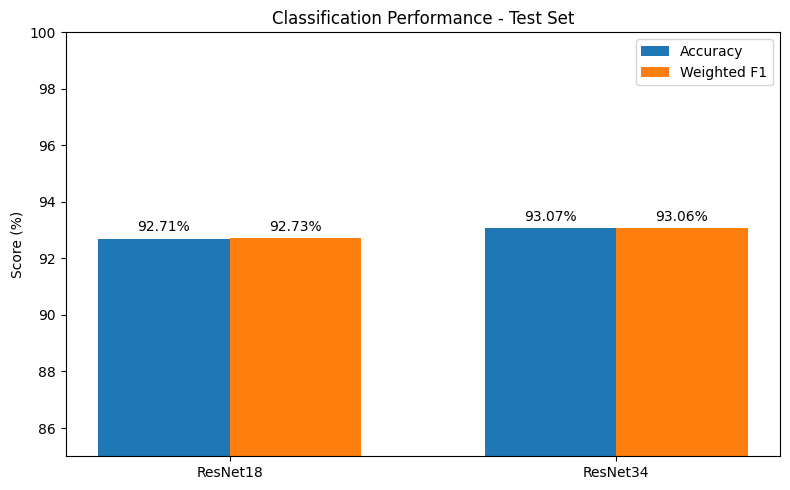

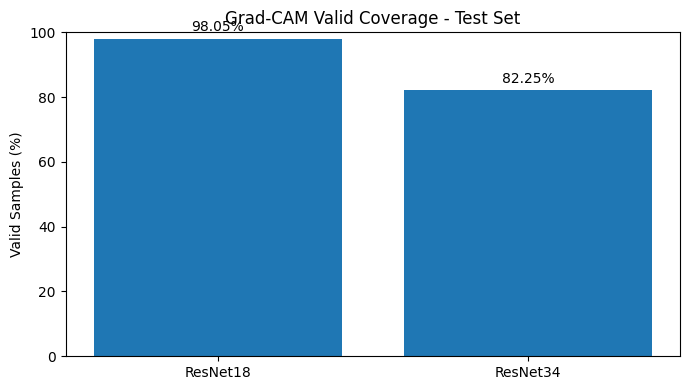

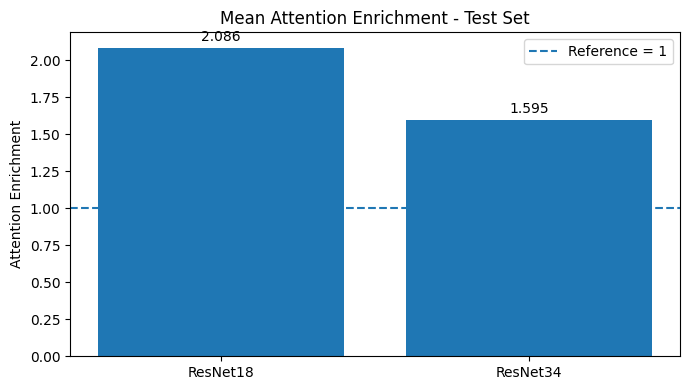

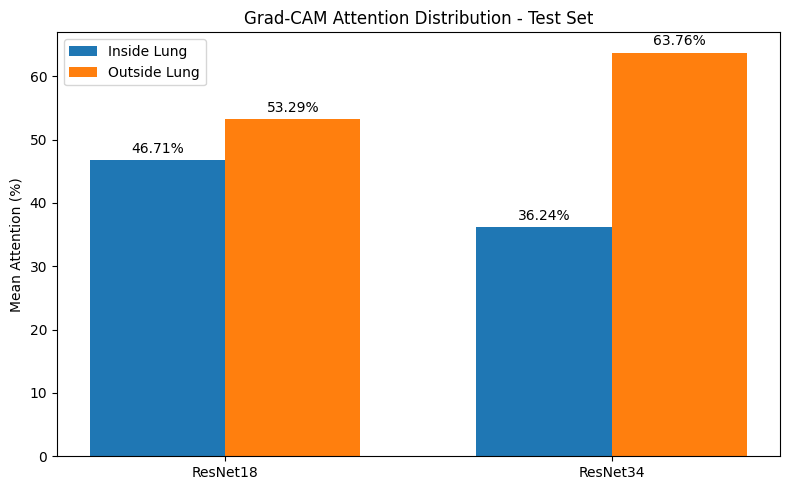

In [ ]:

import matplotlib.pyplot as plt
import numpy as np


models_names = ["ResNet18", "ResNet34"]
accuracy = [92.7052, 93.0699]
weighted_f1 = [92.73, 93.06]

x = np.arange(len(models_names))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(x - width/2, accuracy, width, label="Accuracy")
bars2 = ax.bar(x + width/2, weighted_f1, width, label="Weighted F1")

ax.set_title("Classification Performance - Test Set")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(models_names)
ax.set_ylim(85, 100)
ax.legend()

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

coverage = [98.0547, 82.2492]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(models_names, coverage)

ax.set_title("Grad-CAM Valid Coverage - Test Set")
ax.set_ylabel("Valid Samples (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

enrichment = [2.085524, 1.595290]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(models_names, enrichment)

ax.axhline(1, linestyle="--", label="Reference = 1")
ax.set_title("Mean Attention Enrichment - Test Set")
ax.set_ylabel("Attention Enrichment")
ax.legend()
ax.bar_label(bars, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

inside = [46.7111, 36.2419]
outside = [53.2889, 63.7581]

x = np.arange(len(models_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, inside, width, label="Inside Lung")
bars2 = ax.bar(x + width/2, outside, width, label="Outside Lung")

ax.set_title("Grad-CAM Attention Distribution - Test Set")
ax.set_ylabel("Mean Attention (%)")
ax.set_xticks(x)
ax.set_xticklabels(models_names)
ax.legend()

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

ResNet18, ResNet34, and U-Net are ready.
Grad-CAM will be generated for both classifiers.
Loaded fixed examples from saved JSON.

Fixed Correct Examples:
COVID -> test position 0
Lung_Opacity -> test position 11
Normal -> test position 3
Viral Pneumonia -> test position 1

Fixed Misclassified Examples:
COVID -> test position 78
Lung_Opacity -> test position 35
Normal -> test position 45
Viral Pneumonia -> test position 127
ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: False
Example type: Correct example selected using ResNet18
Test position: 0
Image: COVID-2197.png
True class: COVID

--- ResNet18 ---
Prediction: COVID
Confidence: 86.71%
Correct prediction: True

--- ResNet34 ---
Prediction: COVID
Confidence: 86.78%
Correct prediction: True

--- U-Net Segmentation ---
Predicted lung area: 24.56%
Ground-truth lung area: 23.99%
Mask Dice: 0.9746
Mask IoU: 0.9504


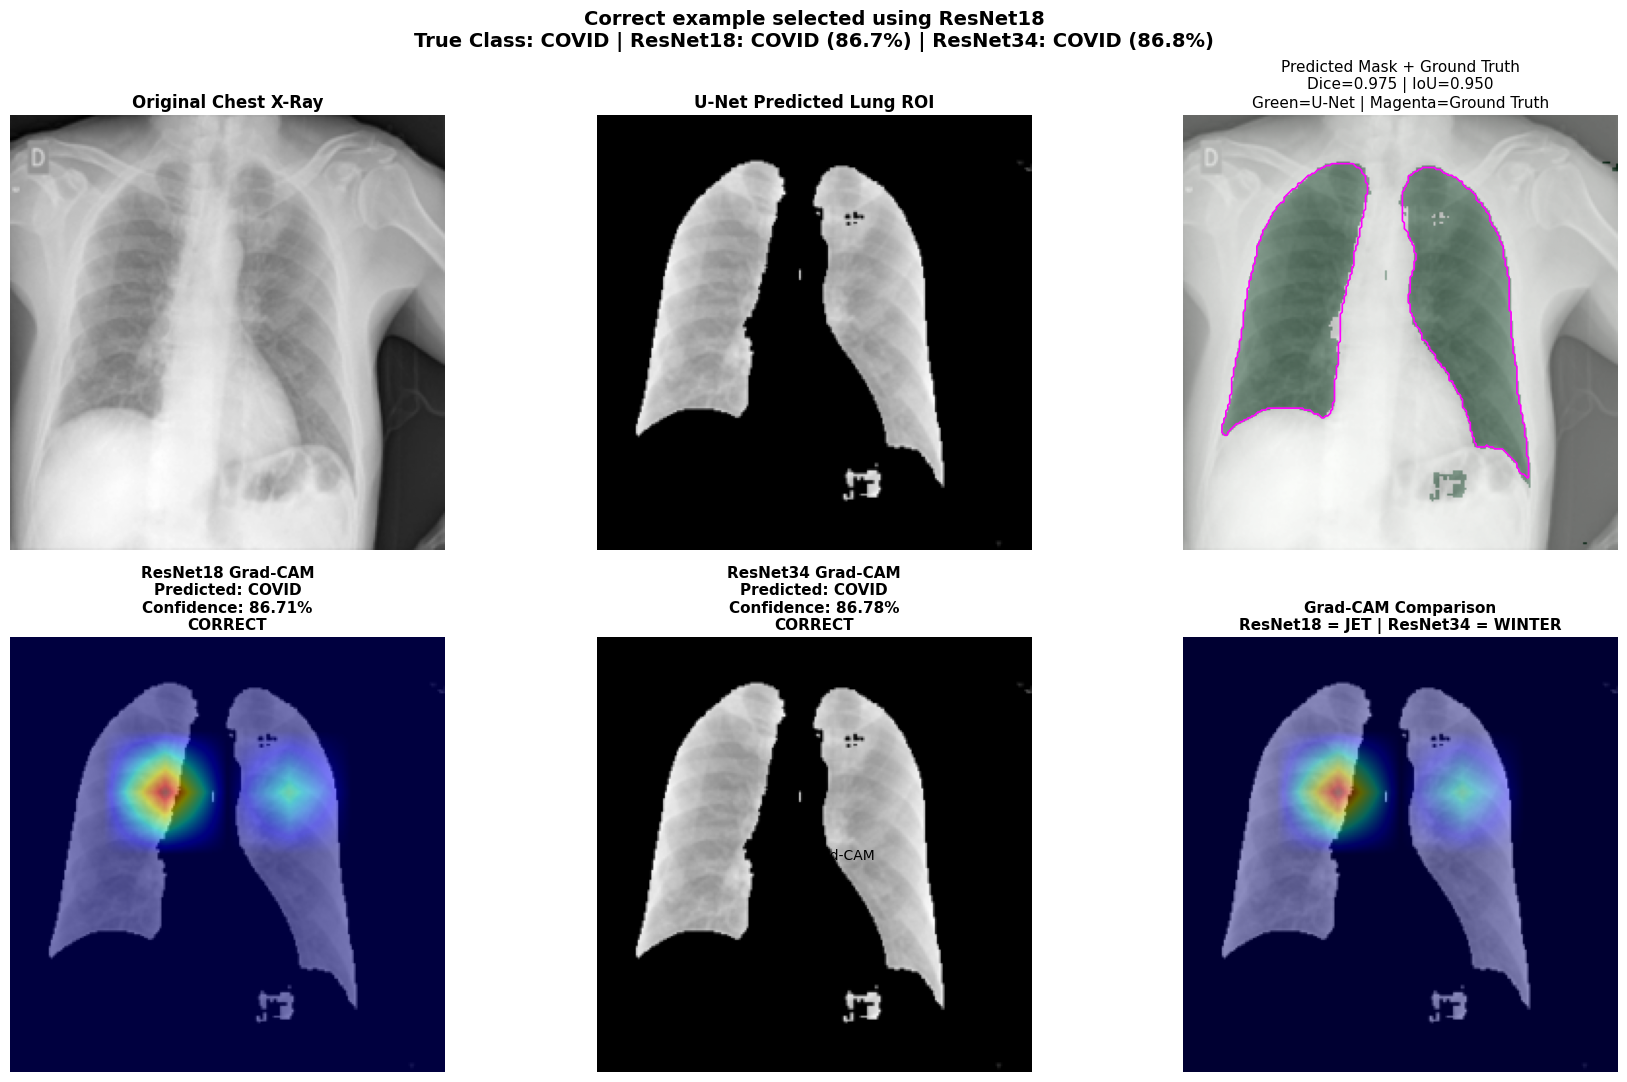

ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: True
Example type: Correct example selected using ResNet18
Test position: 11
Image: Lung_Opacity-3478.png
True class: Lung_Opacity

--- ResNet18 ---
Prediction: Lung_Opacity
Confidence: 68.66%
Correct prediction: True

--- ResNet34 ---
Prediction: Normal
Confidence: 57.89%
Correct prediction: False

--- U-Net Segmentation ---
Predicted lung area: 21.57%
Ground-truth lung area: 23.08%
Mask Dice: 0.9393
Mask IoU: 0.8856


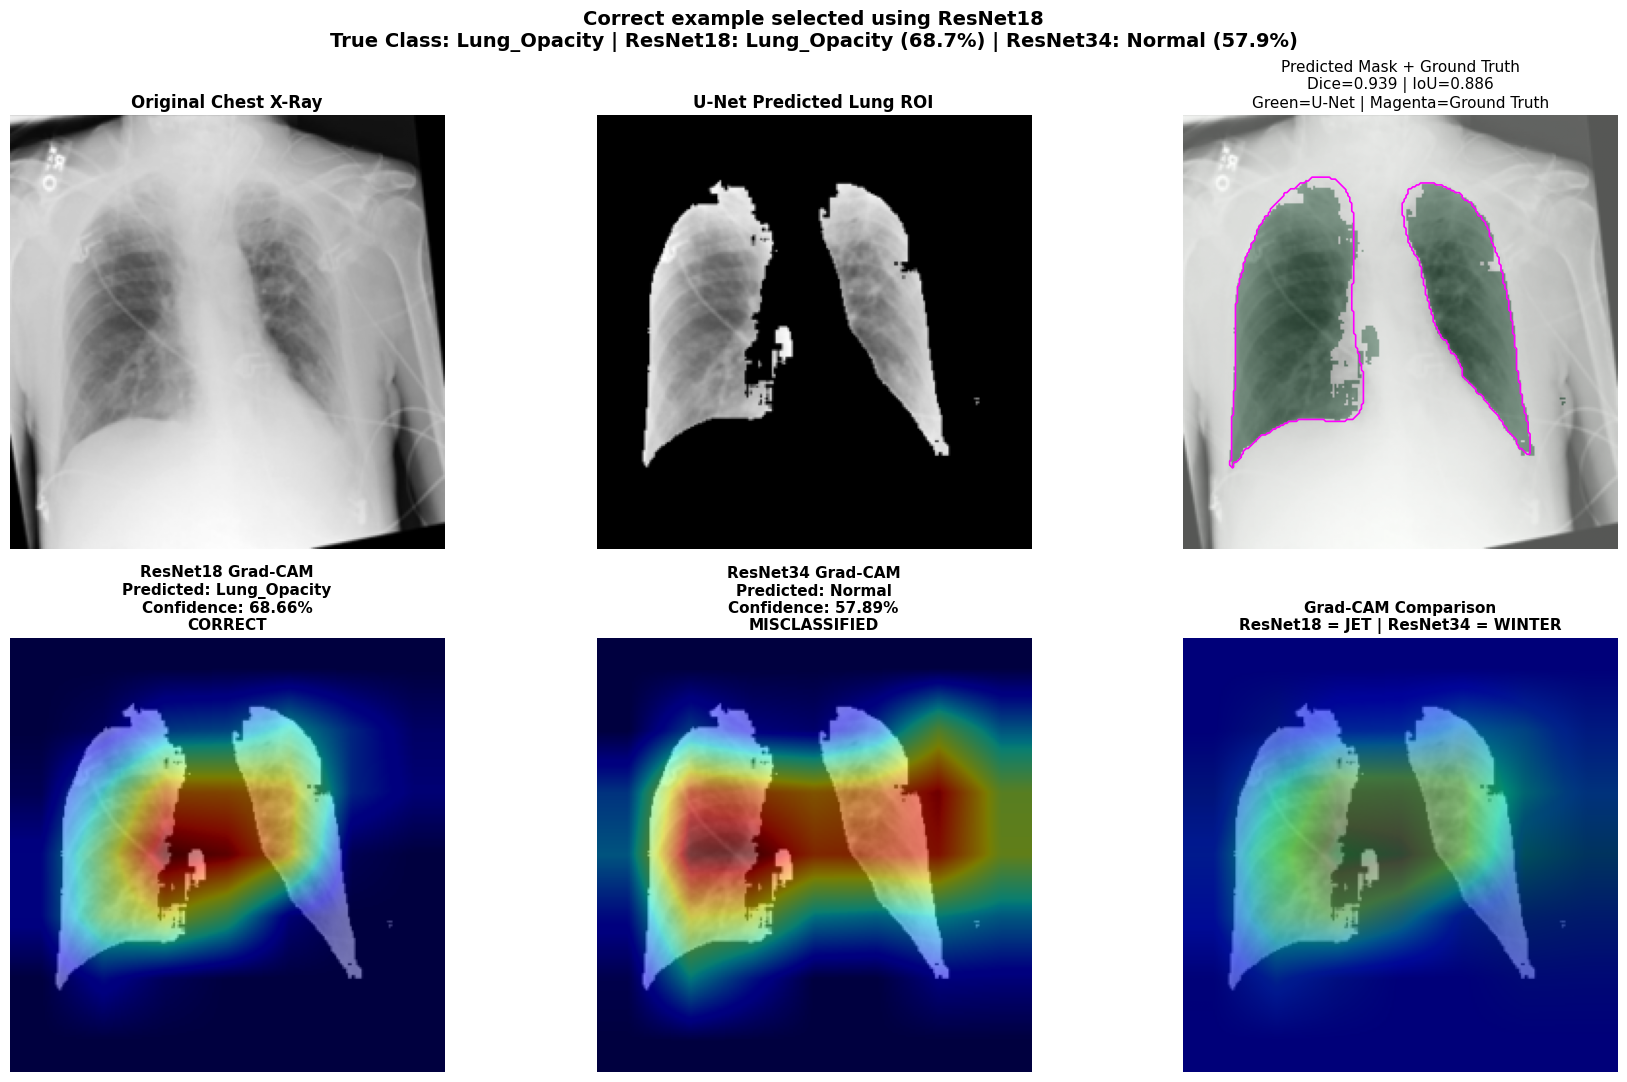

ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: True
Example type: Correct example selected using ResNet18
Test position: 3
Image: Normal-8936.png
True class: Normal

--- ResNet18 ---
Prediction: Normal
Confidence: 91.23%
Correct prediction: True

--- ResNet34 ---
Prediction: Normal
Confidence: 90.29%
Correct prediction: True

--- U-Net Segmentation ---
Predicted lung area: 35.70%
Ground-truth lung area: 35.68%
Mask Dice: 0.9920
Mask IoU: 0.9841


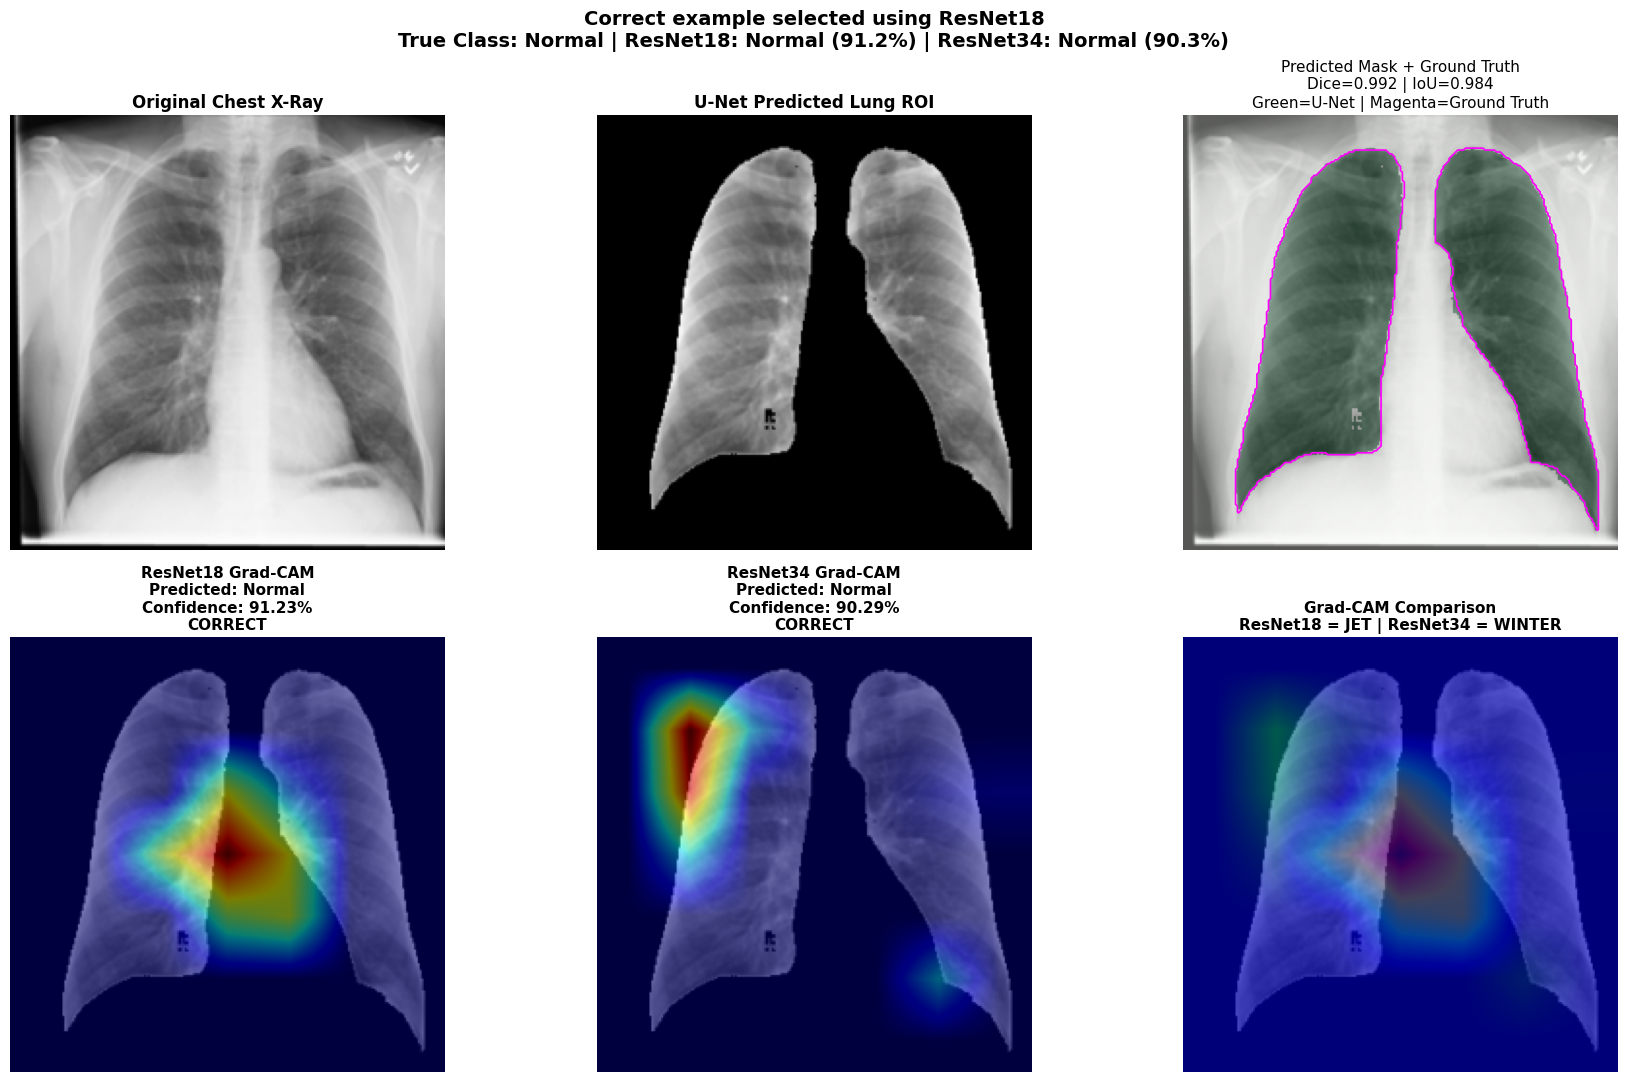

ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: True
Example type: Correct example selected using ResNet18
Test position: 1
Image: Viral Pneumonia-18.png
True class: Viral Pneumonia

--- ResNet18 ---
Prediction: Viral Pneumonia
Confidence: 96.98%
Correct prediction: True

--- ResNet34 ---
Prediction: Viral Pneumonia
Confidence: 97.35%
Correct prediction: True

--- U-Net Segmentation ---
Predicted lung area: 30.60%
Ground-truth lung area: 31.71%
Mask Dice: 0.9606
Mask IoU: 0.9242


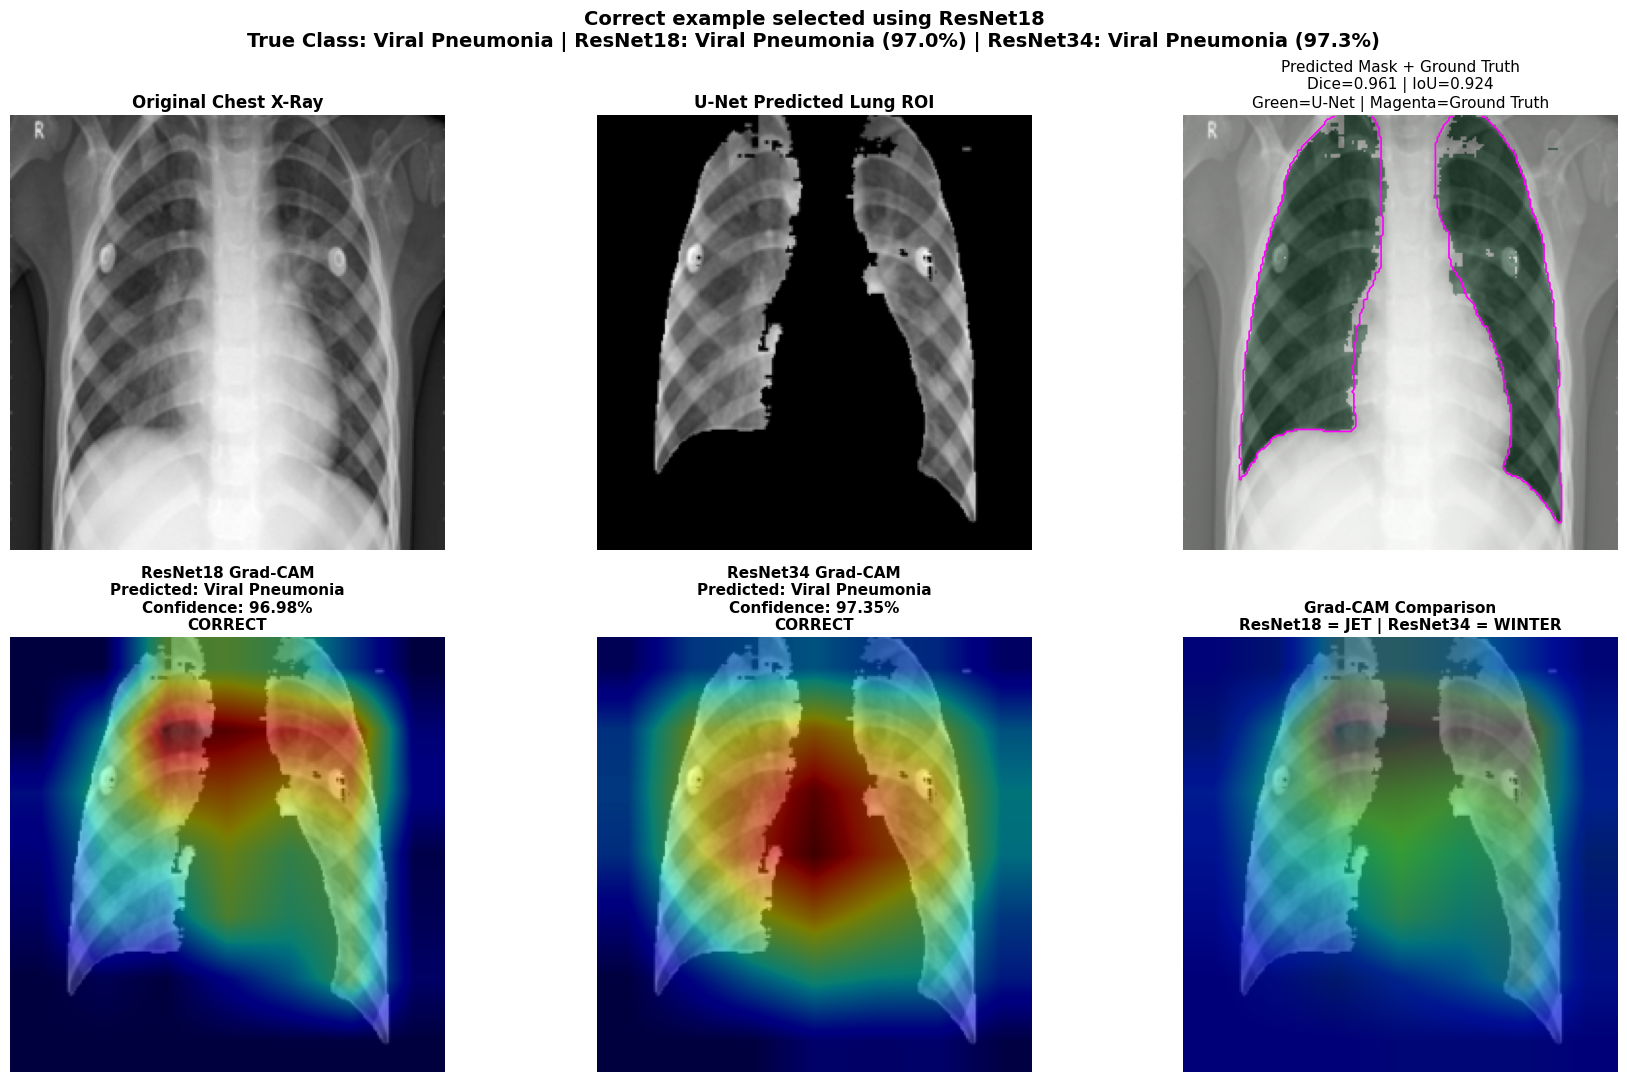

ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: True
Example type: Misclassified example selected using ResNet18
Test position: 78
Image: COVID-1183.png
True class: COVID

--- ResNet18 ---
Prediction: Lung_Opacity
Confidence: 75.63%
Correct prediction: False

--- ResNet34 ---
Prediction: Lung_Opacity
Confidence: 91.81%
Correct prediction: False

--- U-Net Segmentation ---
Predicted lung area: 31.65%
Ground-truth lung area: 30.38%
Mask Dice: 0.9556
Mask IoU: 0.9149


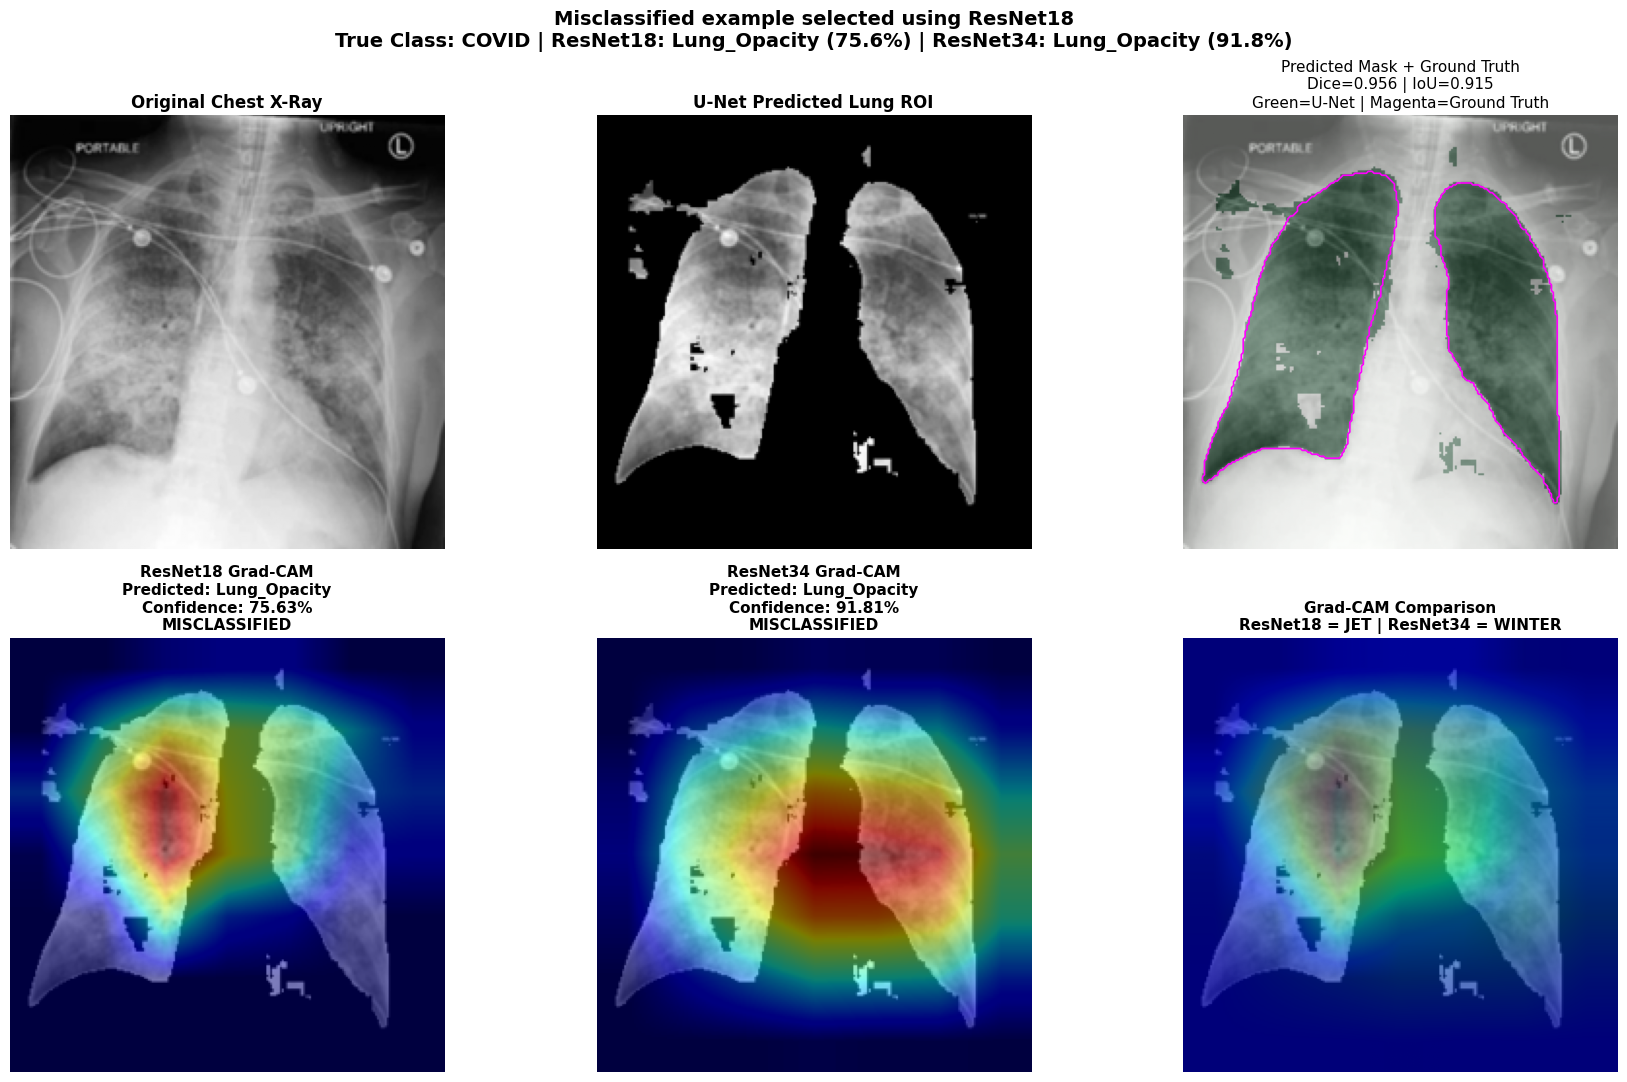

ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: True
Example type: Misclassified example selected using ResNet18
Test position: 35
Image: Lung_Opacity-792.png
True class: Lung_Opacity

--- ResNet18 ---
Prediction: Normal
Confidence: 64.69%
Correct prediction: False

--- ResNet34 ---
Prediction: Lung_Opacity
Confidence: 72.90%
Correct prediction: True

--- U-Net Segmentation ---
Predicted lung area: 11.13%
Ground-truth lung area: 11.25%
Mask Dice: 0.9833
Mask IoU: 0.9672


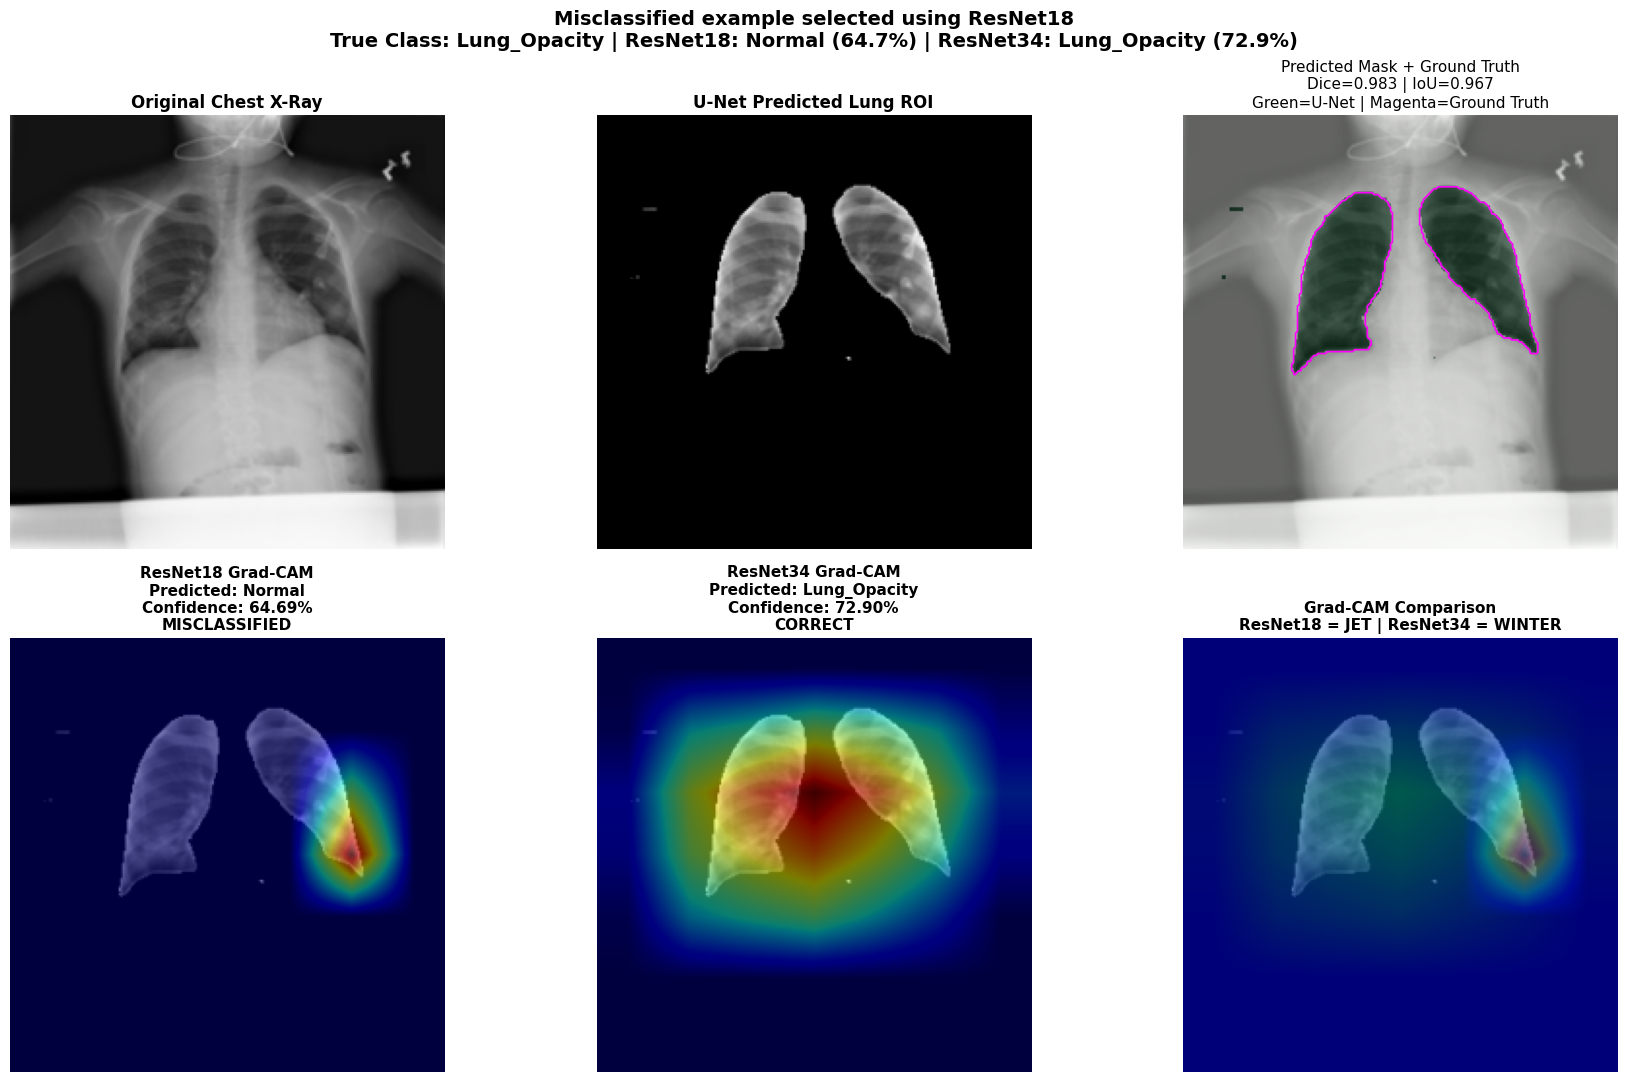

ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: True
Example type: Misclassified example selected using ResNet18
Test position: 45
Image: Normal-2248.png
True class: Normal

--- ResNet18 ---
Prediction: Lung_Opacity
Confidence: 64.73%
Correct prediction: False

--- ResNet34 ---
Prediction: Normal
Confidence: 53.52%
Correct prediction: True

--- U-Net Segmentation ---
Predicted lung area: 14.20%
Ground-truth lung area: 11.99%
Mask Dice: 0.9050
Mask IoU: 0.8264


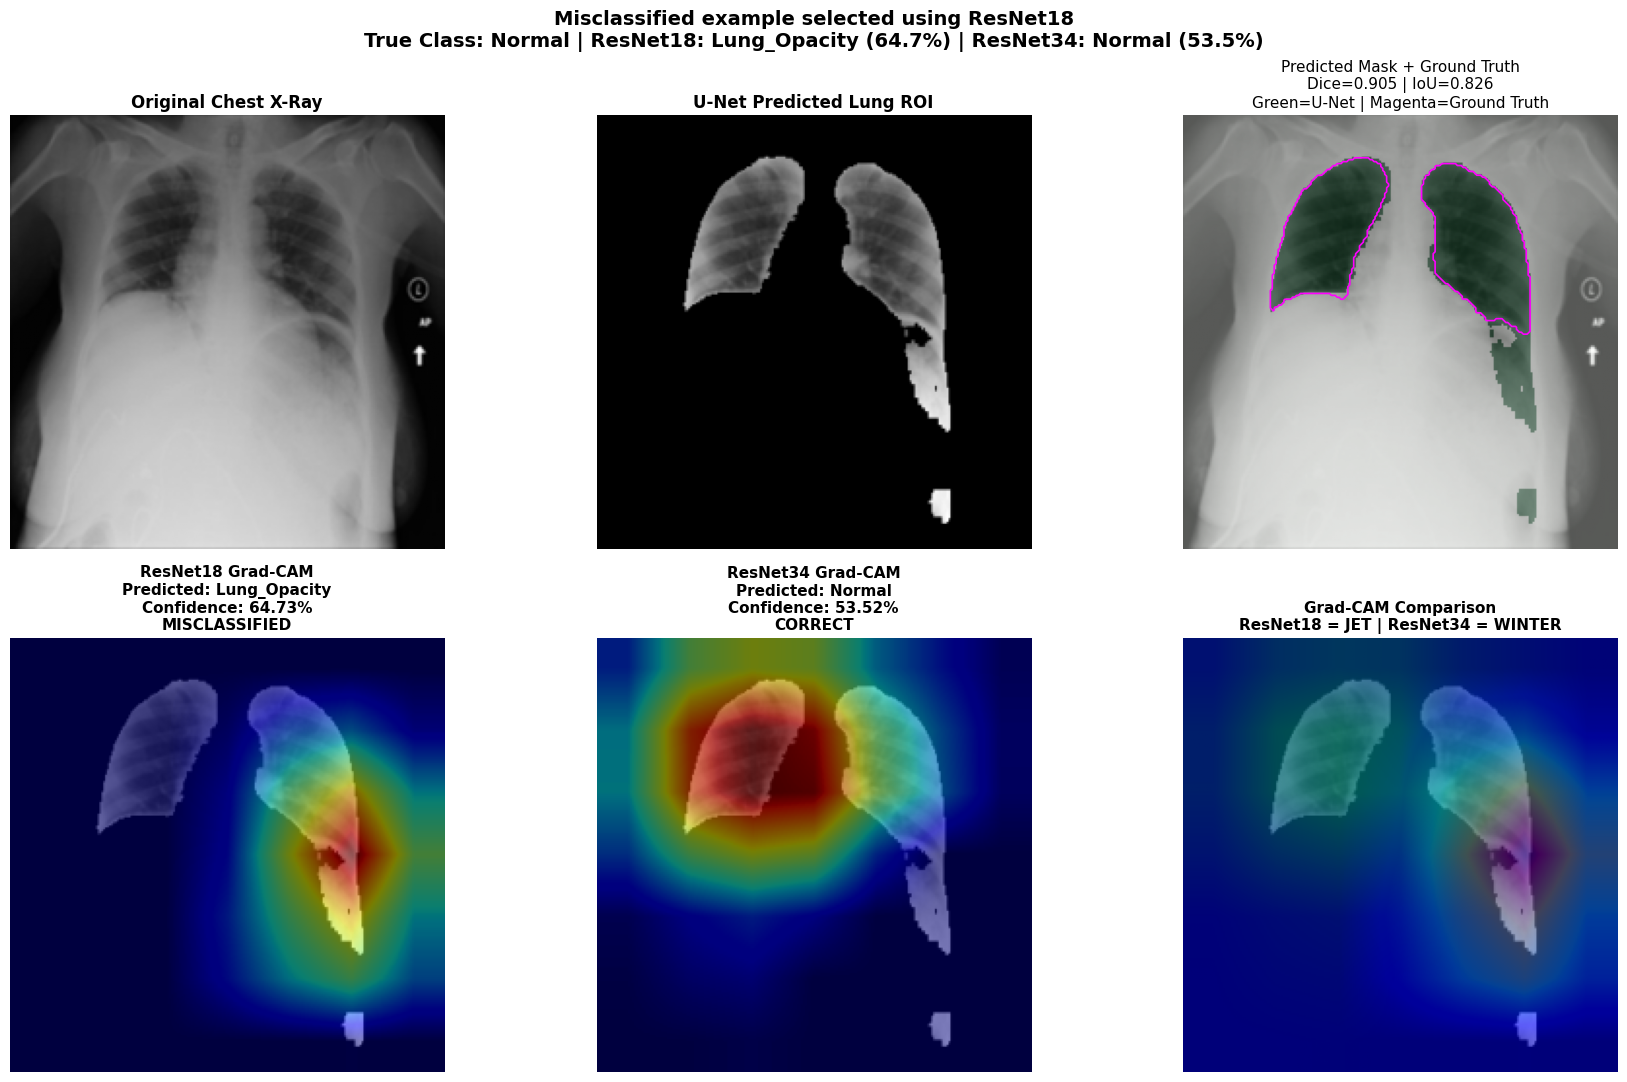

ResNet18 Grad-CAM valid: True
ResNet34 Grad-CAM valid: True
Example type: Misclassified example selected using ResNet18
Test position: 127
Image: Viral Pneumonia-666.png
True class: Viral Pneumonia

--- ResNet18 ---
Prediction: Normal
Confidence: 86.56%
Correct prediction: False

--- ResNet34 ---
Prediction: Normal
Confidence: 55.29%
Correct prediction: False

--- U-Net Segmentation ---
Predicted lung area: 22.46%
Ground-truth lung area: 22.18%
Mask Dice: 0.9720
Mask IoU: 0.9455


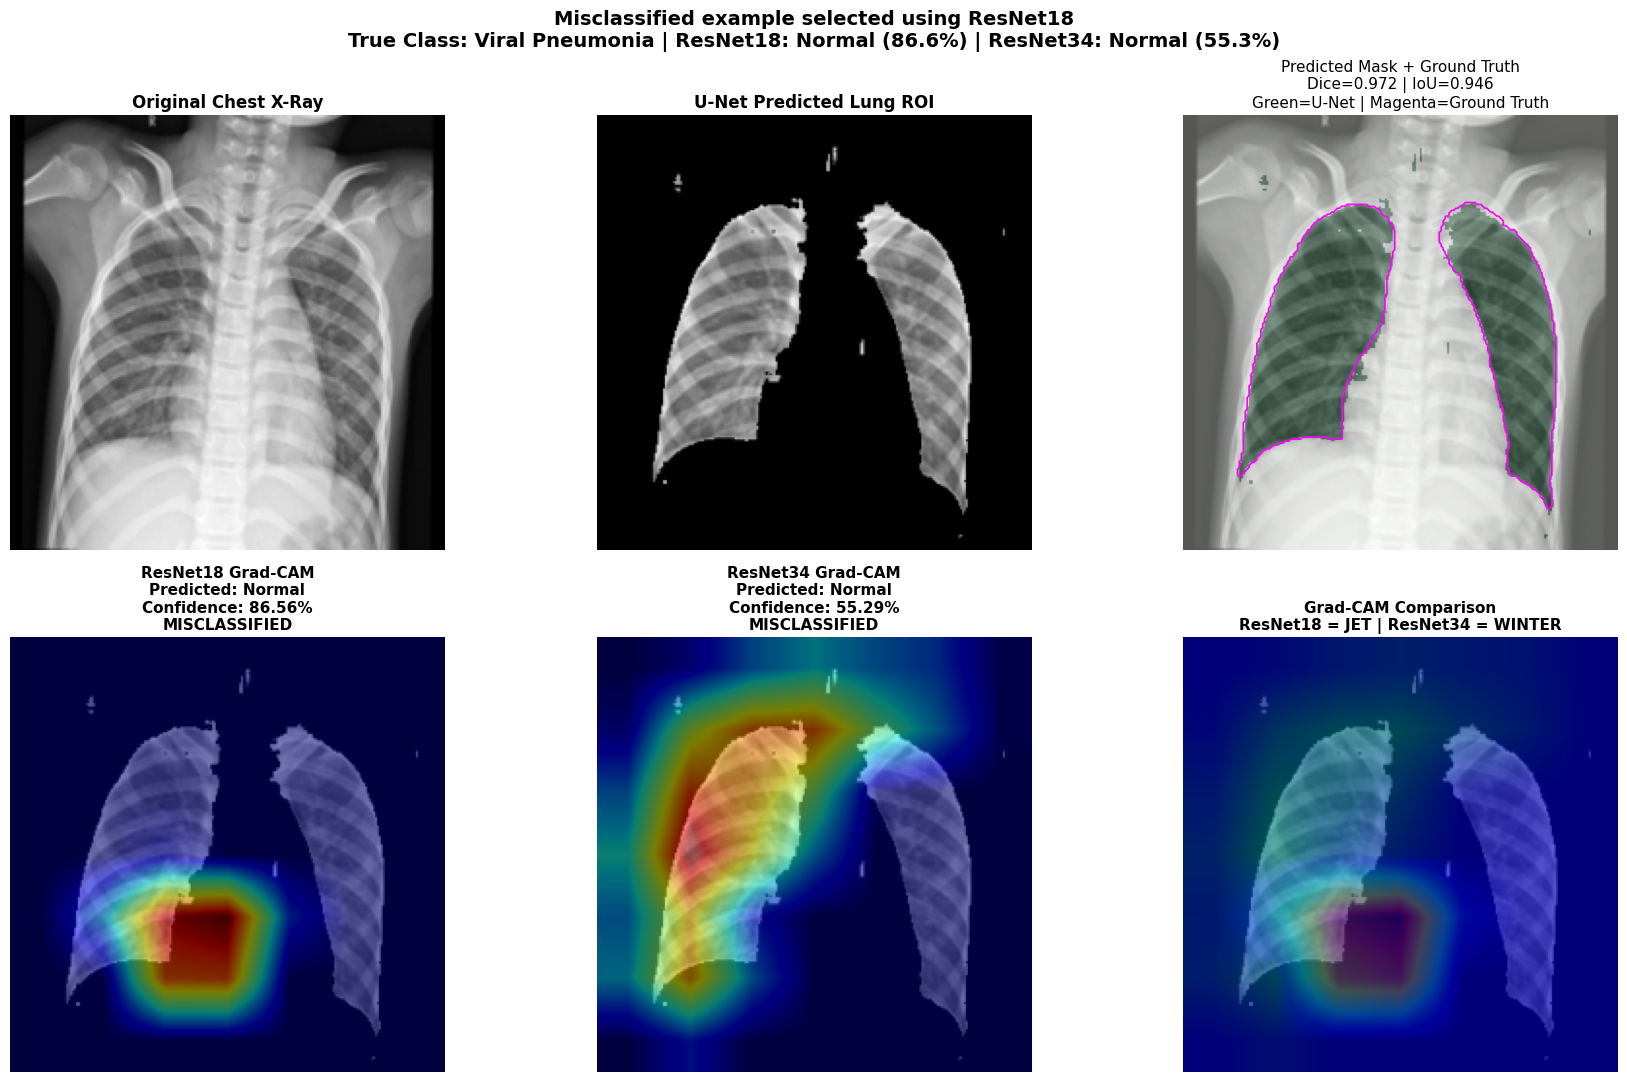


GRAD-CAM COMPARISON FINISHED
Both ResNet18 and ResNet34 were evaluated on the same images.
Grad-CAM illustrates influential image regions; it does not
prove that the model learned medically valid features.


In [ ]:
import os
import json
import hashlib
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


class_names = [
    "COVID",
    "Lung_Opacity",
    "Normal",
    "Viral Pneumonia"
]

EXAMPLES_PATH = "/content/gradcam_resnet18_resnet34_fixed.json"

IMAGE_SIZE = (224, 224)
MASK_SIZE = (256, 256)


def get_final_test_index(test_position):
    return int(test_ds.indices[test_position])


def get_image_path(test_position):
    return image_paths[get_final_test_index(test_position)]


def get_true_label(test_position):
    return int(labels[get_final_test_index(test_position)])


def get_split_fingerprint():
    paths = [
        os.path.abspath(get_image_path(i))
        for i in range(len(test_ds))
    ]

    payload = "\n".join(paths)

    return hashlib.sha256(payload.encode()).hexdigest()


def load_xray(image_path):
    with Image.open(image_path) as image:
        image = image.convert("L")
        return np.asarray(image, dtype=np.float32) / 255.0


def resize_image(
    image,
    size,
    interpolation=Image.Resampling.BILINEAR
):
    pil_image = Image.fromarray(
        (np.clip(image, 0, 1) * 255).astype(np.uint8)
    )

    pil_image = pil_image.resize(size, interpolation)

    return np.asarray(pil_image, dtype=np.float32) / 255.0


def get_ground_truth_mask(image_path):
    mask_path = image_path.replace("/images/", "/masks/")

    if mask_path == image_path or not os.path.exists(mask_path):
        raise FileNotFoundError(
            f"Could not find matching lung mask.\n"
            f"Image path: {image_path}\n"
            f"Expected mask path: {mask_path}"
        )

    with Image.open(mask_path) as image:
        mask = image.convert("L")
        mask = np.asarray(mask, dtype=np.float32)

    return (mask > 127).astype(np.float32)


def resize_binary_mask(mask, size):
    pil_mask = Image.fromarray(
        (mask.astype(np.float32) * 255).astype(np.uint8)
    )

    pil_mask = pil_mask.resize(
        size,
        Image.Resampling.NEAREST
    )

    resized = np.asarray(
        pil_mask,
        dtype=np.float32
    ) / 255.0

    return (resized > 0.5).astype(np.float32)


def get_predicted_lung_mask(
    image,
    unet_model,
    device,
    threshold=0.5
):
    image_tensor = (
        torch.from_numpy(image)
        .float()[None, None]
        .to(device)
    )

    unet_model.eval()

    with torch.no_grad():
        predicted_mask = (
            unet_model(image_tensor)[0, 0]
            .detach()
            .cpu()
            .numpy()
        )

    return (predicted_mask >= threshold).astype(np.float32)


def calculate_mask_metrics(
    predicted_mask,
    ground_truth_mask
):
    pred = predicted_mask > 0.5
    gt = ground_truth_mask > 0.5

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    dice = (
        2.0 * intersection
        / (pred.sum() + gt.sum() + 1e-8)
    )

    iou = intersection / (union + 1e-8)

    return float(dice), float(iou)


def create_roi(image, lung_mask):
    return image * lung_mask


def prepare_roi_for_resnet(roi_image):
    roi_224 = resize_image(
        roi_image,
        IMAGE_SIZE
    )

    roi_tensor = (
        torch.from_numpy(roi_224)
        .float()[None]
        .repeat(3, 1, 1)
    )

    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        dtype=torch.float32
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        dtype=torch.float32
    ).view(3, 1, 1)

    normalized_tensor = (roi_tensor - mean) / std

    return normalized_tensor.unsqueeze(0)


def get_prediction(model, roi_tensor, device):
    model.eval()

    with torch.no_grad():
        output = model(roi_tensor.to(device))

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_label = int(
            probabilities.argmax(dim=1).item()
        )

        confidence = float(
            probabilities[0, predicted_label].item()
        )

    return predicted_label, confidence


def predict_test_position(
    model,
    unet_model,
    test_position,
    device
):
    image_path = get_image_path(test_position)
    true_label = get_true_label(test_position)

    original = load_xray(image_path)

    image_256 = resize_image(
        original,
        MASK_SIZE
    )

    predicted_mask = get_predicted_lung_mask(
        image_256,
        unet_model,
        device
    )

    roi = create_roi(
        image_256,
        predicted_mask
    )

    roi_tensor = prepare_roi_for_resnet(roi)

    predicted_label, confidence = get_prediction(
        model,
        roi_tensor,
        device
    )

    return {
        "test_position": int(test_position),
        "image_path": image_path,
        "true_label": true_label,
        "predicted_label": predicted_label,
        "confidence": confidence
    }


def find_examples(model, unet_model, device):
    correct = {}
    wrong = {}

    for test_position in range(len(test_ds)):

        result = predict_test_position(
            model,
            unet_model,
            test_position,
            device
        )

        true_label = result["true_label"]
        predicted_label = result["predicted_label"]

        if predicted_label == true_label:

            if true_label not in correct:
                correct[true_label] = test_position

        else:

            if true_label not in wrong:
                wrong[true_label] = test_position

        if (
            len(correct) == len(class_names)
            and len(wrong) == len(class_names)
        ):
            break

    return correct, wrong


def load_or_create_examples(
    model,
    unet_model,
    device
):
    fingerprint = get_split_fingerprint()

    if os.path.exists(EXAMPLES_PATH):

        try:
            with open(
                EXAMPLES_PATH,
                "r",
                encoding="utf-8"
            ) as file:
                saved = json.load(file)

            if saved.get("split_fingerprint") == fingerprint:

                correct = {
                    int(k): int(v)
                    for k, v in saved["correct"].items()
                }

                wrong = {
                    int(k): int(v)
                    for k, v in saved["wrong"].items()
                }


                valid_positions = all(
                    0 <= position < len(test_ds)
                    for position in list(correct.values())
                    + list(wrong.values())
                )

                if valid_positions:
                    print("Loaded fixed examples from saved JSON.")
                    return correct, wrong

            print(
                "Saved examples are incompatible with this test split. "
                "Creating new examples."
            )

        except (ValueError, KeyError, OSError) as error:
            print(f"Could not read saved examples: {error}")

    correct, wrong = find_examples(
        model,
        unet_model,
        device
    )

    saved = {
        "split_fingerprint": fingerprint,
        "correct": correct,
        "wrong": wrong
    }

    with open(
        EXAMPLES_PATH,
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(saved, file, indent=4)

    print(f"Saved fixed examples to: {EXAMPLES_PATH}")

    return correct, wrong


def calculate_gradcam(
    model,
    roi_tensor,
    target_label
):
    """
    Return a normalized Grad-CAM map, or None if invalid.
    target_label identifies the class being explained.
    """

    target_layer = model.layer4[-1].conv2

    targets = [
        ClassifierOutputTarget(int(target_label))
    ]

    model.eval()

    with GradCAM(
        model=model,
        target_layers=[target_layer]
    ) as cam:

        grayscale_cam = cam(
            input_tensor=roi_tensor,
            targets=targets
        )[0]

    grayscale_cam = np.asarray(
        grayscale_cam,
        dtype=np.float32
    )


    if not np.isfinite(grayscale_cam).all():
        return None

    cam_min = float(grayscale_cam.min())
    cam_max = float(grayscale_cam.max())


    if cam_max <= 1e-8 or (cam_max - cam_min) <= 1e-8:
        return None


    grayscale_cam = (
        grayscale_cam - cam_min
    ) / (cam_max - cam_min)

    return np.clip(grayscale_cam, 0, 1)




def show_gradcam_example(
    model18,
    model34,
    unet_model,
    test_position,
    example_type,
    device
):

    image_path = get_image_path(test_position)
    true_label = get_true_label(test_position)


    original = load_xray(image_path)

    image_256 = resize_image(
        original,
        MASK_SIZE
    )


    predicted_mask_256 = get_predicted_lung_mask(
        image_256,
        unet_model,
        device
    )


    roi_256 = create_roi(
        image_256,
        predicted_mask_256
    )

    roi_tensor = prepare_roi_for_resnet(
        roi_256
    ).to(device)


    gt_mask = get_ground_truth_mask(image_path)

    pred_mask_224 = resize_binary_mask(
        predicted_mask_256,
        IMAGE_SIZE
    )

    gt_mask_224 = resize_binary_mask(
        gt_mask,
        IMAGE_SIZE
    )

    mask_dice, mask_iou = calculate_mask_metrics(
        pred_mask_224,
        gt_mask_224
    )


    pred18, confidence18 = get_prediction(
        model18,
        roi_tensor,
        device
    )

    pred34, confidence34 = get_prediction(
        model34,
        roi_tensor,
        device
    )


    cam18 = calculate_gradcam(
        model18,
        roi_tensor,
        pred18
    )

    cam34 = calculate_gradcam(
        model34,
        roi_tensor,
        pred34
    )

    print(f"ResNet18 Grad-CAM valid: {cam18 is not None}")
    print(f"ResNet34 Grad-CAM valid: {cam34 is not None}")

    display_original = resize_image(
        original,
        IMAGE_SIZE
    )

    display_roi = resize_image(
        roi_256,
        IMAGE_SIZE
    )

    correct18 = pred18 == true_label
    correct34 = pred34 == true_label

    print("=" * 75)
    print(f"Example type: {example_type}")
    print(f"Test position: {test_position}")
    print(f"Image: {os.path.basename(image_path)}")
    print(f"True class: {class_names[true_label]}")

    print("\n--- ResNet18 ---")
    print(f"Prediction: {class_names[pred18]}")
    print(f"Confidence: {confidence18:.2%}")
    print(f"Correct prediction: {correct18}")

    print("\n--- ResNet34 ---")
    print(f"Prediction: {class_names[pred34]}")
    print(f"Confidence: {confidence34:.2%}")
    print(f"Correct prediction: {correct34}")

    print("\n--- U-Net Segmentation ---")
    print(f"Predicted lung area: {pred_mask_224.mean():.2%}")
    print(f"Ground-truth lung area: {gt_mask_224.mean():.2%}")
    print(f"Mask Dice: {mask_dice:.4f}")
    print(f"Mask IoU: {mask_iou:.4f}")

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 11)
    )


    axes[0, 0].imshow(
        display_original,
        cmap="gray"
    )

    axes[0, 0].set_title(
        "Original Chest X-Ray",
        fontsize=12,
        fontweight="bold"
    )


    axes[0, 1].imshow(
        display_roi,
        cmap="gray"
    )

    axes[0, 1].set_title(
        "U-Net Predicted Lung ROI",
        fontsize=12,
        fontweight="bold"
    )


    axes[0, 2].imshow(
        display_original,
        cmap="gray"
    )

    axes[0, 2].imshow(
        pred_mask_224,
        cmap="Greens",
        alpha=0.35,
        vmin=0,
        vmax=1
    )

    axes[0, 2].contour(
        gt_mask_224,
        levels=[0.5],
        colors=["magenta"],
        linewidths=1.2
    )

    axes[0, 2].set_title(
        f"Predicted Mask + Ground Truth\n"
        f"Dice={mask_dice:.3f} | IoU={mask_iou:.3f}\n"
        f"Green=U-Net | Magenta=Ground Truth",
        fontsize=11
    )


    axes[1, 0].imshow(
        display_roi,
        cmap="gray"
    )

    if cam18 is not None:
        axes[1, 0].imshow(
            cam18,
            cmap="jet",
            alpha=0.50,
            vmin=0,
            vmax=1
        )
    else:
        axes[1, 0].text(
            0.5, 0.5, "Invalid Grad-CAM",
            ha="center",
            va="center",
            transform=axes[1, 0].transAxes
        )

    axes[1, 0].set_title(
        f"ResNet18 Grad-CAM\n"
        f"Predicted: {class_names[pred18]}\n"
        f"Confidence: {confidence18:.2%}\n"
        f"{'CORRECT' if correct18 else 'MISCLASSIFIED'}",
        fontsize=11,
        fontweight="bold"
    )


    axes[1, 1].imshow(
        display_roi,
        cmap="gray"
    )

    if cam34 is not None:
        axes[1, 1].imshow(
            cam34,
            cmap="jet",
            alpha=0.50,
            vmin=0,
            vmax=1
        )
    else:
        axes[1, 1].text(
            0.5, 0.5, "Invalid Grad-CAM",
            ha="center",
            va="center",
            transform=axes[1, 1].transAxes
        )

    axes[1, 1].set_title(
        f"ResNet34 Grad-CAM\n"
        f"Predicted: {class_names[pred34]}\n"
        f"Confidence: {confidence34:.2%}\n"
        f"{'CORRECT' if correct34 else 'MISCLASSIFIED'}",
        fontsize=11,
        fontweight="bold"
    )

    axes[1, 2].imshow(
        display_roi,
        cmap="gray"
    )

    if cam18 is not None:
        axes[1, 2].imshow(
            cam18,
            cmap="jet",
            alpha=0.40,
            vmin=0,
            vmax=1
        )

    if cam34 is not None:
        axes[1, 2].imshow(
            cam34,
            cmap="winter",
            alpha=0.35,
            vmin=0,
            vmax=1
        )

    if cam18 is None and cam34 is None:
        axes[1, 2].text(
            0.5, 0.5, "Both Grad-CAM maps invalid",
            ha="center",
            va="center",
            transform=axes[1, 2].transAxes
        )

    axes[1, 2].set_title(
        "Grad-CAM Comparison\n"
        "ResNet18 = JET | ResNet34 = WINTER",
        fontsize=11,
        fontweight="bold"
    )


    for ax in axes.flat:
        ax.axis("off")

    fig.suptitle(
        f"{example_type}\n"
        f"True Class: {class_names[true_label]} | "
        f"ResNet18: {class_names[pred18]} ({confidence18:.1%}) | "
        f"ResNet34: {class_names[pred34]} ({confidence34:.1%})",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()



required_variables = [
    "resnet18",
    "resnet34",
    "unet_model",
    "test_ds",
    "image_paths",
    "labels",
    "DEVICE"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "These notebook variables are missing: "
        + ", ".join(missing_variables)
        + ". Run the model-loading and dataset cells first."
    )



resnet18.eval()
resnet34.eval()
unet_model.eval()

print("ResNet18, ResNet34, and U-Net are ready.")
print("Grad-CAM will be generated for both classifiers.")



correct_examples, wrong_examples = load_or_create_examples(
    resnet18,
    unet_model,
    DEVICE
)


print("\nFixed Correct Examples:")

for label, position in sorted(correct_examples.items()):
    print(
        f"{class_names[label]} -> test position {position}"
    )


print("\nFixed Misclassified Examples:")

for label, position in sorted(wrong_examples.items()):
    print(
        f"{class_names[label]} -> test position {position}"
    )

for label, position in sorted(correct_examples.items()):
    show_gradcam_example(
        resnet18,
        resnet34,
        unet_model,
        position,
        "Correct example selected using ResNet18",
        DEVICE
    )

for label, position in sorted(wrong_examples.items()):
    show_gradcam_example(
        resnet18,
        resnet34,
        unet_model,
        position,
        "Misclassified example selected using ResNet18",
        DEVICE
    )


print("\n" + "=" * 75)
print("GRAD-CAM COMPARISON FINISHED")
print("Both ResNet18 and ResNet34 were evaluated on the same images.")
print("Grad-CAM illustrates influential image regions; it does not")
print("prove that the model learned medically valid features.")
print("=" * 75)